# Predicting Sleep Duration from Daily Activity
## Data Exploration, Preparation and Modelling - Iteration 1

### Project goal
This project investigates whether a participant’s daytime activity can help predict how long they sleep the following night.

### Dataset
This project uses the [PMData dataset](https://osf.io/vx4bk/overview), which contains records of participants’ activity, sleep, exercise, wellbeing, and physical measurements.

Original files will be kept unchanged. All preparation happens in memory, inside this notebook.

### Purpose of this notebook
This notebook covers the whole project in one place. It combines data exploration and preprocessing to:

- Understand the file structure, available measurements, participant identifiers, and dates.
- Verify the sleep target and select relevant input variables.
- Identify missing values, duplicates, and inconsistent records.
- Clean and combine the selected data across participants.
- Match each day’s information to the following night’s main sleep episode.
- Document the decisions made along the way.

The prepared table is then used to train and evaluate the model later in this same notebook.

### Preventing information leakage
We predict sleep duration at 21:00, using activity recorded since the participant woke up. Steps and recorded activity sessions after 21:00 are not included. Days without a recorded wake-up time before 21:00 are excluded.

Measurements from the night being predicted, such as its sleep stages or sleep score, must not be used as inputs. Transformations that learn from the data, such as scaling or filling missing values using averages, will be fitted on training data in the modelling stage.

### Expected output
The intended output is a table with **one row per participant per prediction day**, containing participant and date identifiers, selected daytime summaries up to 21:00, the previous nights' sleep, and the following night's sleep duration as the target.

Once the table is ready, the notebook continues with model training and evaluation, and concludes with a summary of the decisions made, data limitations, and remaining questions.


### Notebook navigation

[Iteration 1 — exploration and first models](#1.-Setup) · [Iteration 2 — additional features](#Iteration-2)

## 1. Setup
Import pandas to read and work with tables, `Path` to build file paths, and matplotlib with seaborn for plots. Add other libraries only when needed.


In [512]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# One seed for everything random, so the results are the same every run.
SEED = 0

DATA_DIR = Path("../data/raw/pmdata")
# Each participant has a folder named p01, p02, and so on.
participant_folders = sorted(DATA_DIR.glob("p[0-9][0-9]"))

if not participant_folders:
    raise FileNotFoundError(f"No participant folders found in {DATA_DIR.resolve()}")


## 2. Which participants have the relevant files?
Start with sleep, steps, and exercise sessions (which contain the active minutes) for a simple first model. Check Google Docs and wellness as optional additions. Food images are outside this first model’s scope.

The table below checks whether files exist; it does not yet check whether their dates overlap or their values are complete. Missing optional files are not a reason to exclude a participant.


In [513]:
files_to_check = {
    "sleep": "fitbit/sleep.json",
    "steps": "fitbit/steps.json",
    "exercise": "fitbit/exercise.json",
    "google_reports_optional": "googledocs/reporting.csv",
    "wellness_optional": "pmsys/wellness.csv",
}

availability_rows = []
for folder in participant_folders:
    row = {"participant_id": folder.name}
    for name, relative_path in files_to_check.items():
        row[name] = (folder / relative_path).is_file()
    availability_rows.append(row)

availability = pd.DataFrame(availability_rows).set_index("participant_id")
availability


,sleep,steps,exercise,google_reports_optional,wellness_optional
participant_id,,,,,
p01,True,True,True,True,True
p02,True,True,True,True,True
p03,True,True,True,True,True
p04,True,True,True,True,True
p05,True,True,True,True,True
p06,True,True,True,True,True
p07,True,True,True,True,True
p08,True,True,True,True,True
p09,True,True,True,True,True


From this table, we can see that participant 15 does not have Google Forms data, which includes daily meals, weight, fluid intake, and alcohol consumption. This could matter if we use those inputs later, but our initial model will use sleep, steps, and activity minutes, so we can keep participant 15 for now.

All participants have the files we need to start. Next, we need to check what is actually inside the sleep files, because having a file does not mean every night was recorded.


## 3. Is the sleep data usable?
We need sleep duration because it is the value our model will predict. Before using it, we need to know how many nights each participant has recorded, whether any required values are missing, and whether there are any duplicates.

First, load the main-sleep records into one table. Keep the participant, sleep ID, date, start and end times, and minutes asleep. The ID helps us recognize repeated episodes; the times will help us match sleep to daytime activity later. We are not loading the detailed sleep stages because we do not need them for this target.


In [514]:
# Select the needed fields and give them clearer names.
sleep_columns = {
    "logId": "sleep_id",
    "dateOfSleep": "sleep_date",
    "startTime": "start_time",
    "endTime": "end_time",
    "minutesAsleep": "minutes_asleep",
}

sleep_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/sleep.json", convert_dates=False)
    # Keep main sleep rather than naps, and record who it belongs to.
    main_sleep = records.loc[records["mainSleep"].eq(True), list(sleep_columns)].copy()
    main_sleep["participant_id"] = folder.name
    sleep_tables.append(main_sleep)

# Combine the participants into one table.
sleep = pd.concat(sleep_tables, ignore_index=True).rename(columns=sleep_columns)
sleep.head(10)


,sleep_id,sleep_date,start_time,end_time,minutes_asleep,participant_id
0,24486013387,2019-11-02,2019-11-02 00:09:30,2019-11-02T07:19:30.000,378,p01
1,24497341340,2019-11-03,2019-11-03 00:32:00,2019-11-03T07:34:30.000,378,p01
2,24507914069,2019-11-04,2019-11-03 23:55:30,2019-11-04T06:35:00.000,361,p01
3,24521896102,2019-11-05,2019-11-05 00:22:30,2019-11-05T06:25:00.000,326,p01
4,24534036899,2019-11-06,2019-11-06 00:25:30,2019-11-06T06:29:30.000,341,p01
5,24544805751,2019-11-07,2019-11-06 23:45:30,2019-11-07T05:52:00.000,312,p01
6,24544805751,2019-11-07,2019-11-06 23:45:30,2019-11-07T05:52:00.000,312,p01
7,24557456459,2019-11-08,2019-11-07 23:48:30,2019-11-08T06:21:00.000,360,p01
8,24568877484,2019-11-09,2019-11-09 00:31:30,2019-11-09T07:02:30.000,344,p01
9,24579324569,2019-11-10,2019-11-10 00:15:30,2019-11-10T07:18:00.000,382,p01


### Check coverage and basic problems
Convert dates and durations so we can count and compare them. Unreadable values become missing values. A row needs attention if a required value is missing, its duration is not positive, or its end time is not after its start time.

Use the same date window for everyone: the earliest through latest main-sleep date in the downloaded data. This measures coverage across the available dataset, not just each person’s own first-to-last record. It does not establish when each person was expected to participate.


In [515]:
# Convert dates and durations; unreadable values become missing.
for column in ["sleep_date", "start_time", "end_time"]:
    sleep[column] = pd.to_datetime(sleep[column], errors="coerce", format="mixed")
sleep["minutes_asleep"] = pd.to_numeric(sleep["minutes_asleep"], errors="coerce")

study_dates = pd.date_range(sleep["sleep_date"].min(), sleep["sleep_date"].max())
print(f"Observed dataset window: {study_dates[0]:%d %b %Y} to {study_dates[-1]:%d %b %Y}")
print(f"Dates in this window: {len(study_dates)}")


Observed dataset window: 01 Nov 2019 to 01 Apr 2020
Dates in this window: 153


In the table below:
- **Records** counts all main-sleep entries; 
- **Recorded nights** counts different sleep dates.
- **Missing nights** counts dates in the shared window with no main-sleep entry. A missing night does not mean zero sleep but rather that there is no available data for it (days without a recorded wake-up are left out later, and nights without a record stay as missing values, not zeros).
- **Rows to check** counts entries with missing or invalid required values.
- **Extra repeated IDs** counts entries beyond the first with the same participant and sleep ID. Matching copies are removed below; differing records must be investigated.


In [516]:
# Flag incomplete or invalid rows, and extra copies of each sleep ID.
needs_check = (
    sleep.isna().any(axis=1)
    | sleep["minutes_asleep"].le(0)
    | sleep["end_time"].le(sleep["start_time"])
)
repeated_ids = sleep["sleep_id"].notna() & sleep.duplicated(["participant_id", "sleep_id"])

# Summarise by participant without looping through their records.
sleep_coverage = (
    sleep.assign(needs_check=needs_check, repeated_ids=repeated_ids)
    .groupby("participant_id").agg(**{
        "Records": ("sleep_date", "size"),
        "Recorded nights": ("sleep_date", "nunique"),
        "Rows to check": ("needs_check", "sum"),
        "Extra repeated IDs": ("repeated_ids", "sum"),
    })
    .rename_axis("Participant")
)
sleep_coverage.insert(2, "Missing nights", len(study_dates) - sleep_coverage["Recorded nights"])
sleep_coverage


,Records,Recorded nights,Missing nights,Rows to check,Extra repeated IDs
Participant,,,,,
p01,155,150,3,0,5
p02,146,142,11,0,4
p03,81,78,75,0,3
p04,149,144,9,0,5
p05,123,118,35,0,5
p06,155,150,3,0,5
p07,146,142,11,0,4
p08,137,133,20,0,4
p09,141,136,17,0,5


The repeated entries are identical copies, so we keep one of each.


In [517]:
# Remove exact duplicates without changing the raw files.
sleep_clean = sleep.drop_duplicates(ignore_index=True)
print(f"Removed {len(sleep) - len(sleep_clean)} duplicates; {len(sleep_clean):,} sleep records remain.")


Removed 61 duplicates; 1,881 sleep records remain.


We also calculate the average sleep across the last three calendar nights, as this was found during the research we did. Each night is averaged with the two calendar nights before it. If some of them are missing, the average uses the nights that were recorded. Later, each day is matched to the average ending on its morning, so it only uses nights that have already ended before 21:00.

In [518]:
# Average each night with the two calendar nights before it.
# Rows are sorted by participant and date, so the results line up with the table.
sleep_clean = sleep_clean.sort_values(["participant_id", "sleep_date"]).reset_index(drop=True)
sleep_clean["avg_sleep_last_3_nights"] = (
    sleep_clean
    .groupby("participant_id")
    .rolling("3D", on="sleep_date")["minutes_asleep"]
    .mean()
    .to_numpy()
)

sleep_clean[["participant_id", "sleep_date", "minutes_asleep", "avg_sleep_last_3_nights"]].head(10)

,participant_id,sleep_date,minutes_asleep,avg_sleep_last_3_nights
0,p01,2019-11-02,378,378.000000
1,p01,2019-11-03,378,378.000000
2,p01,2019-11-04,361,372.333333
3,p01,2019-11-05,326,355.000000
4,p01,2019-11-06,341,342.666667
5,p01,2019-11-07,312,326.333333
6,p01,2019-11-08,360,337.666667
7,p01,2019-11-09,344,338.666667
8,p01,2019-11-10,382,362.000000
9,p01,2019-11-11,318,348.000000


Now that the sleep records are prepared, we use each participant's recorded wake-up time to define that day's activity window.

The window starts when their main sleep ends and finishes at 21:00. Later, we will add up the activity recorded within that window.

In [519]:
# Use the main sleep's end as the recorded wake-up time.
prediction_days = sleep_clean[[
    "participant_id",
    "sleep_date",
    "end_time"
]].rename(columns={
    "sleep_date": "date",
    "end_time": "wake_up_time"
})

# Set a prediction time of 21:00 for each date.
prediction_days["prediction_time"] = (
    prediction_days["date"] + pd.Timedelta(hours=21)
)

# We need a recorded wake-up time that is earlier than the cutoff.
prediction_days = prediction_days.loc[
    prediction_days["wake_up_time"].notna()
    & (prediction_days["wake_up_time"] < prediction_days["prediction_time"])
].copy()

prediction_days.head(10)

,participant_id,date,wake_up_time,prediction_time
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00
5,p01,2019-11-07,2019-11-07 05:52:00,2019-11-07 21:00:00
6,p01,2019-11-08,2019-11-08 06:21:00,2019-11-08 21:00:00
7,p01,2019-11-09,2019-11-09 07:02:30,2019-11-09 21:00:00
8,p01,2019-11-10,2019-11-10 07:18:00,2019-11-10 21:00:00
9,p01,2019-11-11,2019-11-11 06:05:00,2019-11-11 21:00:00


We have cleaned the sleep records and defined the activity windows. Next, we will prepare the activity measurements before combining them with sleep.

## 4. Prepare the activity records
We will use steps and active minutes to describe each participant’s daytime activity. First, we inspect the files to understand their dates and values.

In [520]:
# Inspect one participant's steps before loading everyone's data.
steps_example = pd.read_json(
    participant_folders[4] / "fitbit/steps.json",
    convert_dates=False
)

steps_example.sample(15, random_state=SEED)

,dateTime,value
29516,2019-12-10 12:54:00,0
85376,2020-02-19 16:52:00,48
81347,2020-02-14 21:56:00,0
51503,2020-01-07 17:06:00,0
79259,2020-02-12 18:45:00,106
79236,2020-02-12 18:22:00,0
19393,2019-11-28 10:17:00,0
84409,2020-02-18 16:29:00,0
69761,2020-01-30 10:28:00,0
101743,2020-03-18 15:20:00,0


We can see that step measurements are spread out through the day, so now we will combine all steps for a single day into one, instead of having so many entries. But before that we need to check for exact duplicates and delete them if there are any.

In [521]:
# Check whether any minute appears more than once.
print(f" Number of duplicate rows is: {steps_example["dateTime"].duplicated().sum()}")

 Number of duplicate rows is: 0


Since there are no duplicates we will continue with the merging of entries. For each day, we use the wake-up time and the 21:00 prediction time from `prediction_days`, and only add up the steps taken between them, so steps after the prediction time are not included.

In [522]:
# Convert the timestamps so pandas can group them by date.
steps_example["dateTime"] = pd.to_datetime(steps_example["dateTime"])
steps_example["date"] = steps_example["dateTime"].dt.normalize()

# Match each minute to that day's wake-up time and 21:00 cutoff.
example_days = prediction_days.loc[
    prediction_days["participant_id"] == participant_folders[4].name
]
example_window = steps_example.merge(example_days, on="date")
example_window = example_window.loc[
    (example_window["dateTime"] >= example_window["wake_up_time"])
    & (example_window["dateTime"] < example_window["prediction_time"])
]

# Add up the steps taken between waking up and 21:00 for each day.
daily_steps = (
    example_window
    .groupby("date")["value"]
    .sum()
    .rename("steps")
    .reset_index()
)

daily_steps.sample(10, random_state=SEED)

,date,steps
10,2019-11-16,6538
59,2020-01-07,19216
95,2020-03-09,8373
91,2020-03-05,26
7,2019-11-13,12572
86,2020-02-16,10057
26,2019-12-03,7810
112,2020-03-26,7696
22,2019-11-29,9815
94,2020-03-08,8555


Now that we know how to turn the step values into daily ones, we will continue with exploring the moderately active minutes file to see if we can actually make use of it.

In [523]:
# Read Fitbit's separate measurement of moderately active minutes.
moderate_example = pd.read_json(
    participant_folders[0] / "fitbit/moderately_active_minutes.json",
    convert_dates=False
)

moderate_example.head(10)

,dateTime,value
0,2019-11-01 00:00:00,58
1,2019-11-02 00:00:00,43
2,2019-11-03 00:00:00,63
3,2019-11-04 00:00:00,23
4,2019-11-05 00:00:00,22
5,2019-11-06 00:00:00,10
6,2019-11-07 00:00:00,11
7,2019-11-08 00:00:00,38
8,2019-11-09 00:00:00,31
9,2019-11-10 00:00:00,34


Moderately active minutes are recorded as daily totals, which wouldn't really fit our use case as we need recorded activity from wake up time all the way up until 21:00. Using the full totals could include activity that happened after our prediction, so we cannot use them as today's inputs. We need records that show when the activity happened. There is also an `exercise.json` file, so we will look inside it to see whether it gives us the timings and activity levels we need.

In [524]:
exercise_tables = []

# Read each participant's sessions and attach their ID.
for folder in participant_folders:
    records = pd.read_json(
        folder / "fitbit/exercise.json",
        convert_dates=False
    )
    records["participant_id"] = folder.name
    exercise_tables.append(records)

exercise_records = pd.concat(exercise_tables, ignore_index=True)

exercise_records.head(15)

,logId,activityName,activityTypeId,activityLevel,averageHeartRate,calories,duration,activeDuration,steps,logType,...,source,tcxLink,speed,pace,vo2Max,participant_id,swimLengths,poolLength,poolLengthUnit,customHeartRateZones
0,26451905128,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,192,1331000,1331000,1878.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
1,26455950499,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",94.0,302,2202000,2202000,2786.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
2,26467488515,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",98.0,354,2458000,2458000,3035.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
3,26520401069,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",97.0,145,1024000,1024000,1284.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
4,26538035127,Walk,90013,"[{'minutes': 3, 'name': 'sedentary'}, {'minute...",93.0,121,973000,973000,1065.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
5,26517400839,Run,90009,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",144.0,396,1465000,1460000,3901.0,tracker,...,"{'type': 'tracker', 'name': 'Versa 2', 'id': '...",https://www.fitbit.com/activities/exercise/265...,9.341901,385.360523,{'vo2Max': 47.37765},p01,NaN,NaN,NaN,NaN
6,26601718322,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",97.0,252,1844000,1844000,2094.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
7,26613177504,Walk,90013,"[{'minutes': 1, 'name': 'sedentary'}, {'minute...",97.0,454,3123000,3123000,4185.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
8,26777647969,Walk,90013,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",106.0,470,2867000,2867000,4698.0,auto_detected,...,NaN,NaN,NaN,NaN,NaN,p01,NaN,NaN,NaN,NaN
9,26664863611,Run,90009,"[{'minutes': 0, 'name': 'sedentary'}, {'minute...",146.0,339,1264000,1260000,3384.0,tracker,...,"{'type': 'tracker', 'name': 'Versa 2', 'id': '...",https://www.fitbit.com/activities/exercise/266...,9.713571,370.615486,{'vo2Max': 47.012370000000004},p01,NaN,NaN,NaN,NaN


This table gives us way more information we can work with. Now we are able to see activities throughout the day per participant, also with the type of activity it is, the start time and the duration in ms. It would be nice for the model also to know what type of activity it was and the start end time of it, but I feel like this is way too complex to figure out for the 1st iteration. So I will just sum up all the activity minutes types between wake up time and 21:00. Research showed that intense activity before bed led to decrease in sleep duration, it would be interesting to investigate on my own, so we will also add a `min_since_last_activity` and `last_activity` for the type of activity it was.

In [525]:
# Expand the activity breakdown while keeping each session's details.
levels = pd.json_normalize(
    exercise_records.to_dict("records"),
    record_path="activityLevel",
    meta=["participant_id", "logId", "activityName", "startTime", "duration"]
).drop_duplicates()

# Put the activity categories into separate columns.
exercise_sessions = levels.pivot(
    index=["participant_id", "logId", "activityName", "startTime", "duration"],
    columns="name",
    values="minutes"
).reset_index()

exercise_sessions.columns.name = None
exercise_sessions = exercise_sessions.rename(columns={
    "logId": "session_id",
    "activityName": "activity_type",
    "startTime": "start_time",
    "lightly": "lightly_active_minutes",
    "fairly": "moderately_active_minutes",
    "very": "very_active_minutes"
})

# Calculate the end time and express duration in minutes.
exercise_sessions["start_time"] = pd.to_datetime(
    exercise_sessions["start_time"]
)
duration_ms = pd.to_numeric(exercise_sessions["duration"])

exercise_sessions["end_time"] = (
    exercise_sessions["start_time"]
    + pd.to_timedelta(duration_ms, unit="ms")
)
exercise_sessions["duration_minutes"] = duration_ms / 60_000

# Keep the fields needed for the daily totals and last-activity details.
exercise_sessions = exercise_sessions[[
    "participant_id",
    "session_id",
    "activity_type",
    "start_time",
    "end_time",
    "duration_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]].sort_values("start_time").reset_index(drop=True)

exercise_sessions.head(10)

,participant_id,session_id,activity_type,start_time,end_time,duration_minutes,lightly_active_minutes,moderately_active_minutes,very_active_minutes
0,p03,26446767579,Walk,2019-11-01 11:45:06,2019-11-01 12:24:21,39.250000,4,3,29
1,p01,26451905128,Walk,2019-11-01 14:56:32,2019-11-01 15:18:43,22.183333,0,8,14
2,p05,26472425317,Walk,2019-11-01 18:56:06,2019-11-01 19:14:01,17.916667,3,5,9
3,p01,26455950499,Walk,2019-11-01 19:03:11,2019-11-01 19:39:53,36.700000,1,12,23
4,p06,26421235751,Interval Workout,2019-11-02 08:44:54,2019-11-02 09:25:00,40.100000,0,0,40
5,p06,26465868505,Walk,2019-11-02 11:45:28,2019-11-02 12:07:39,22.183333,0,3,19
6,p01,26467488515,Walk,2019-11-02 13:26:38,2019-11-02 14:07:36,40.966667,0,11,30
7,p05,26480520277,Walk,2019-11-02 23:47:02,2019-11-03 00:12:38,25.600000,0,4,21
8,p06,26476567208,Walk,2019-11-02 23:47:34,2019-11-03 00:03:47,16.216667,0,3,13
9,p09,26477744222,Walk,2019-11-03 00:17:30,2019-11-03 01:45:10,87.666667,23,14,31


### Prepare activity data for all participants
For each participant, we sum the steps taken between wake-up and 21:00, and add up the activity minutes from exercise sessions in the same window. Sessions still going at 21:00 are left out, so no activity after the prediction time is counted. A day with no recorded session gets 0 session minutes. We also keep the type of the last session (`last_activity`) and how many minutes before 21:00 it ended (`min_since_last_activity`). A day with no session gets `None` as its last activity, because nothing happened that day.

In [526]:
# Load every participant's minute-level steps.
step_tables = []
for folder in participant_folders:
    records = pd.read_json(folder / "fitbit/steps.json", convert_dates=False)
    records["participant_id"] = folder.name
    step_tables.append(records.drop_duplicates())

all_steps = pd.concat(step_tables, ignore_index=True)
all_steps["dateTime"] = pd.to_datetime(all_steps["dateTime"])
all_steps["date"] = all_steps["dateTime"].dt.normalize()

# Keep only the steps taken between waking up and 21:00.
steps_in_window = all_steps.merge(prediction_days, on=["participant_id", "date"])
steps_in_window = steps_in_window.loc[
    (steps_in_window["dateTime"] >= steps_in_window["wake_up_time"])
    & (steps_in_window["dateTime"] < steps_in_window["prediction_time"])
]
window_steps = (
    steps_in_window
    .groupby(["participant_id", "date"])["value"]
    .sum()
    .rename("steps")
    .reset_index()
)

# Keep sessions that started after waking up and ended by 21:00.
sessions = exercise_sessions.assign(date=exercise_sessions["start_time"].dt.normalize())
sessions = sessions.merge(prediction_days, on=["participant_id", "date"])
sessions = sessions.loc[
    (sessions["start_time"] >= sessions["wake_up_time"])
    & (sessions["end_time"] <= sessions["prediction_time"])
]

# Add up the activity minutes of those sessions for each day.
minute_columns = [
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]
window_sessions = (
    sessions
    .groupby(["participant_id", "date"])
    .agg(session_count=("session_id", "size"), **{c: (c, "sum") for c in minute_columns})
    .reset_index()
)

# Describe the last session before 21:00.
last_session = sessions.sort_values("end_time").groupby(["participant_id", "date"]).tail(1)
last_session = last_session.assign(
    min_since_last_activity=(
        last_session["prediction_time"] - last_session["end_time"]
    ).dt.total_seconds() / 60
)[["participant_id", "date", "activity_type", "min_since_last_activity"]]
last_session = last_session.rename(columns={"activity_type": "last_activity"})

# Start from the prediction days, so every row has a wake-up time before 21:00.
daily_activity = prediction_days
for table in [window_steps, window_sessions, last_session]:
    daily_activity = daily_activity.merge(
        table, on=["participant_id", "date"], how="left", validate="one_to_one"
    )

# A day without a recorded session has zero session minutes.
session_columns = ["session_count"] + minute_columns
daily_activity[session_columns] = daily_activity[session_columns].fillna(0).astype(int)

# A day without a recorded session has no last activity.
daily_activity["last_activity"] = daily_activity["last_activity"].fillna("None")

daily_activity.head(10)

,participant_id,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00,11063.0,1,0,11,30,Walk,412.400000
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00,13045.0,0,0,0,0,None,NaN
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00,7373.0,0,0,0,0,None,NaN
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00,9574.0,1,13,0,0,Walk,76.366667
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00,5189.0,0,0,0,0,None,NaN
5,p01,2019-11-07,2019-11-07 05:52:00,2019-11-07 21:00:00,4994.0,0,0,0,0,None,NaN
6,p01,2019-11-08,2019-11-08 06:21:00,2019-11-08 21:00:00,9724.0,1,5,11,15,Walk,324.733333
7,p01,2019-11-09,2019-11-09 07:02:30,2019-11-09 21:00:00,12912.0,0,0,0,0,None,NaN
8,p01,2019-11-10,2019-11-10 07:18:00,2019-11-10 21:00:00,13549.0,1,2,8,38,Walk,742.716667
9,p01,2019-11-11,2019-11-11 06:05:00,2019-11-11 21:00:00,8232.0,0,0,0,0,None,NaN


## 5. Combine activity and sleep
Now we put activity and sleep together in one table. Each row will show a participant’s activity for one day, how they slept the night before, and how they slept the following night.
Sleep is dated by the morning it ends. For example, Tuesday night’s sleep is saved under Wednesday’s date, so we match it to Tuesday’s activity.

From the night before, we keep the bedtime, how long they slept, and the 3-night average. Its end time is the wake-up time, which is already in the table. From the following night, we only keep how long they slept, because that is what we predict. Its start and end times describe the night we are predicting, so we leave them out to prevent information leakage.

In [527]:
# Sleep ending on the activity date is the previous night's sleep.
# Its end is the wake-up time, which is already in the table.
previous_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "start_time": "previous_bedtime",
    "minutes_asleep": "previous_sleep_minutes",
}).drop(columns=["sleep_id", "end_time"])

# Keep only the following night's duration, which is what we predict.
following_sleep = sleep_clean.rename(columns={
    "sleep_date": "date",
    "minutes_asleep": "next_sleep_minutes",
})[["participant_id", "date", "next_sleep_minutes"]]

# Match sleep ending on Wednesday to Tuesday's activity.
following_sleep["date"] = following_sleep["date"] - pd.Timedelta(days=1)

# Combine by participant and date, keeping all activity rows.
combined_data = (
    daily_activity
    .merge(
        previous_sleep,
        on=["participant_id", "date"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        following_sleep,
        on=["participant_id", "date"],
        how="left",
        validate="one_to_one"
    )
)

combined_data.head()

,participant_id,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,previous_bedtime,previous_sleep_minutes,avg_sleep_last_3_nights,next_sleep_minutes
0,p01,2019-11-02,2019-11-02 07:19:30,2019-11-02 21:00:00,11063.0,1,0,11,30,Walk,412.400000,2019-11-02 00:09:30,378,378.000000,378.0
1,p01,2019-11-03,2019-11-03 07:34:30,2019-11-03 21:00:00,13045.0,0,0,0,0,None,NaN,2019-11-03 00:32:00,378,378.000000,361.0
2,p01,2019-11-04,2019-11-04 06:35:00,2019-11-04 21:00:00,7373.0,0,0,0,0,None,NaN,2019-11-03 23:55:30,361,372.333333,326.0
3,p01,2019-11-05,2019-11-05 06:25:00,2019-11-05 21:00:00,9574.0,1,13,0,0,Walk,76.366667,2019-11-05 00:22:30,326,355.000000,341.0
4,p01,2019-11-06,2019-11-06 06:29:30,2019-11-06 21:00:00,5189.0,0,0,0,0,None,NaN,2019-11-06 00:25:30,341,342.666667,312.0


Now we will use a box plot to see how sleep duration differs between participants. We want to spot unusually short or long nights, large differences between people, and participants whose sleep varies much more than the rest.

These differences do not automatically mean the data is wrong. We will investigate unusual records before deciding whether to exclude anything.

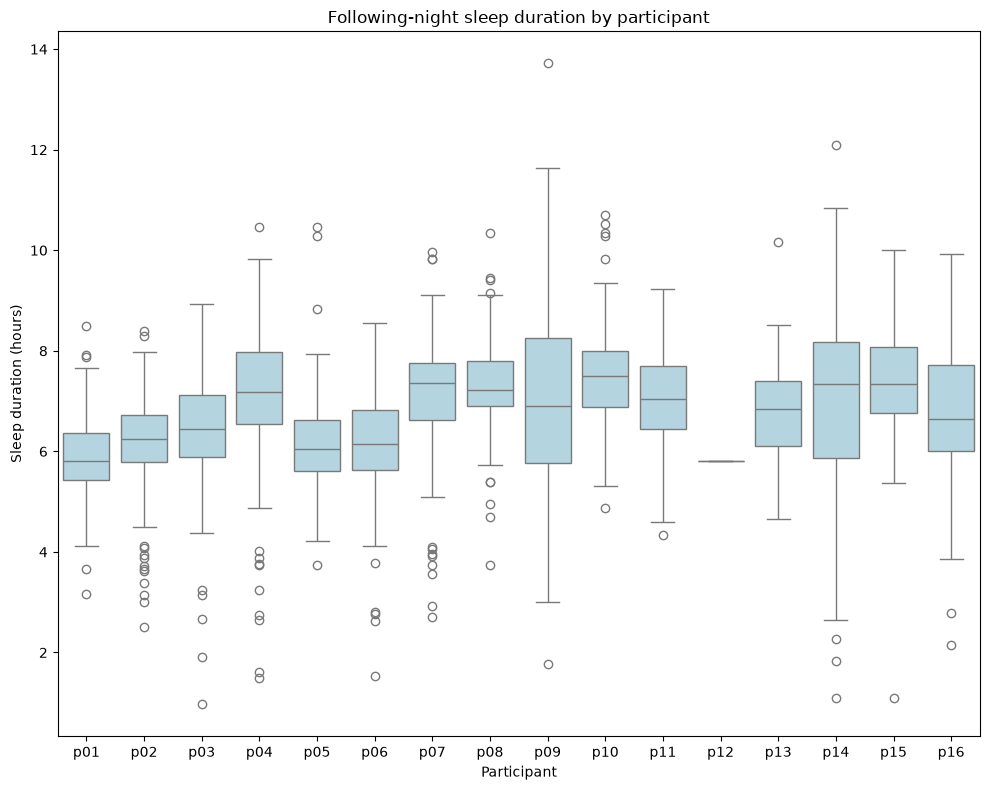

In [528]:
import matplotlib.pyplot as plt


# Convert sleep to hours without changing the combined table.
plot_data = combined_data.assign(
    sleep_hours=combined_data["next_sleep_minutes"] / 60
)

plt.figure(figsize=(10,8))

sns.boxplot(
    data=plot_data,
    x="participant_id",
    y="sleep_hours",
    order=sorted(plot_data["participant_id"].unique()),
    color="lightblue"
)

plt.title("Following-night sleep duration by participant")
plt.xlabel("Participant")
plt.ylabel("Sleep duration (hours)")
plt.tight_layout()
plt.show()

Based on this boxplot we can see that some participants like p09, p14, have large spreads, p12 barely has any nights left, some participants like p02, p04, p07 have lots of outliers, which could mean that there was an issue with their wearables, or maybe it wasn't worn properly, or just that there isn't a significant amount of data we can work with, further analysis of those participants should be done to determine whether we should drop them.

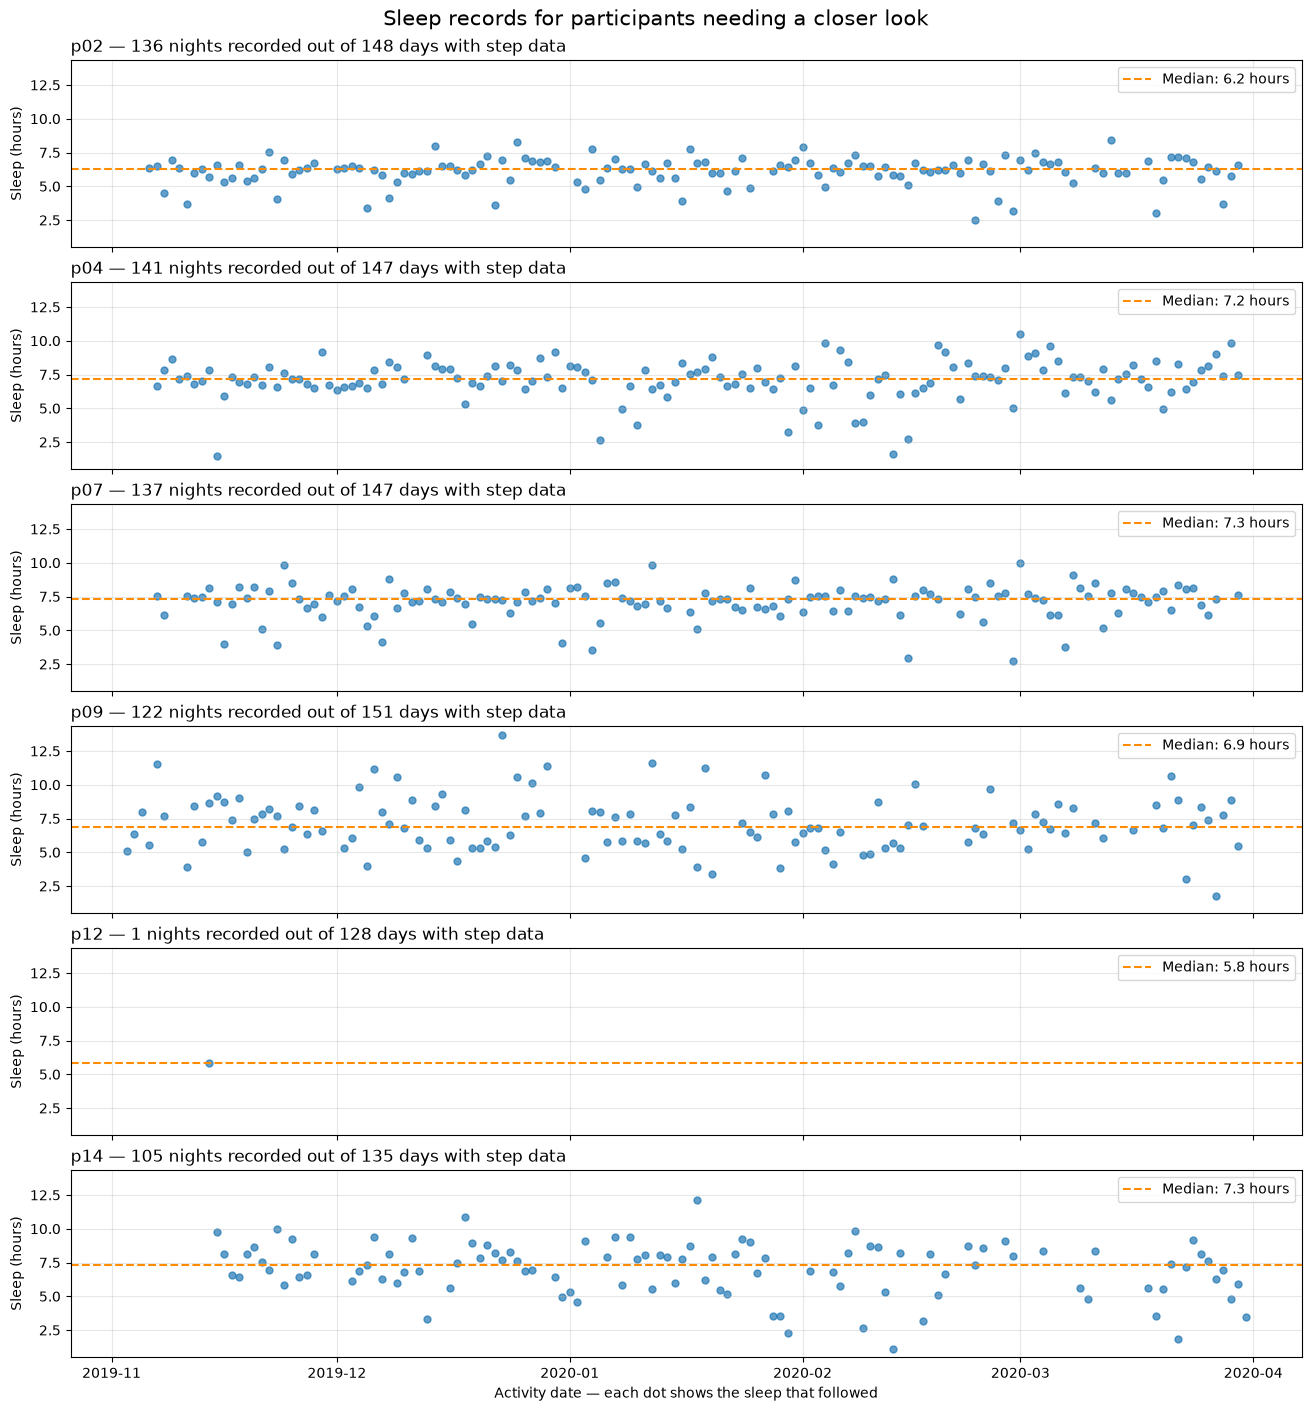

In [529]:
participants_to_check = ["p02", "p04", "p07", "p09", "p12", "p14"]

# Count the days each participant has any step data.
step_days = all_steps.groupby("participant_id")["date"].nunique()

fig, axes = plt.subplots(
    len(participants_to_check), 1,
    figsize=(13, 14),
    sharex=True,
    sharey=True,
    layout="constrained"
)

for ax, participant in zip(axes, participants_to_check):
    person = (
        combined_data.loc[combined_data["participant_id"] == participant]
        .sort_values("date")
    )

    # Only nights with a recorded duration appear as dots.
    recorded = person.dropna(subset=["next_sleep_minutes"])

    ax.scatter(
        recorded["date"],
        recorded["next_sleep_minutes"] / 60,
        s=25,
        alpha=0.7
    )

    # Mark this participant's median sleep duration.
    median_hours = recorded["next_sleep_minutes"].median() / 60

    ax.axhline(
        median_hours,
        color="darkorange",
        linestyle="--",
        label=f"Median: {median_hours:.1f} hours"
    )
    ax.legend(loc="upper right")

    ax.set_title(
        f"{participant} — {len(recorded)} nights recorded "
        f"out of {step_days[participant]} days with step data",
        loc="left"
    )
    ax.set_ylabel("Sleep (hours)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Activity date — each dot shows the sleep that followed")
fig.suptitle("Sleep records for participants needing a closer look", fontsize=15)

plt.show()

Just like I thought we can see that p12 doesn't have many sleep entries, despite having steps recorded on almost all days, so I am leaning towards excluding all p12 related rows. The rest of the participants seem to have outliers, but they are way more manageable to work with, so for the time being I will keep them in the dataset.

In [530]:
# Remove every row that belongs to p12.
rows_before = len(combined_data)
combined_data = combined_data.loc[combined_data["participant_id"] != "p12"].reset_index(drop=True)

print(f"Removed {rows_before - len(combined_data)} p12 rows; {len(combined_data):,} rows remain.")

Removed 6 p12 rows; 1,870 rows remain.


Now that we have excluded p12 from the final table, we need to check how many nights actually will have our TARGET VARIABLE next_sleep_minutes, all other rows can be excluded as our models won't have the final answer they should strive for. The easiest way to do that is by using the describe() function and compare the counts.

In [531]:
combined_data.describe()

,date,wake_up_time,prediction_time,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,min_since_last_activity,previous_bedtime,previous_sleep_minutes,avg_sleep_last_3_nights,next_sleep_minutes
count,1870,1870,1870,1853.000000,1870.000000,1870.000000,1870.000000,1870.000000,1161.000000,1870,1870.000000,1870.000000,1762.000000
mean,2020-01-15 15:39:27.914438,2020-01-15 23:54:10.331550,2020-01-16 12:39:27.914438,10191.196438,1.020321,3.656150,5.438503,30.732620,322.166896,2020-01-15 16:06:59.181818,406.818182,406.248752,406.770148
min,2019-11-01 00:00:00,2019-11-01 04:03:00,2019-11-01 21:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000,2019-11-01 00:59:30,54.000000,54.000000,58.000000
25%,2019-12-11 00:00:00,2019-12-11 07:28:52.500000,2019-12-11 21:00:00,5770.000000,0.000000,0.000000,0.000000,0.000000,179.650000,2019-12-10 23:56:37.500000,360.000000,368.083333,360.000000
50%,2020-01-15 00:00:00,2020-01-15 06:31:15,2020-01-15 21:00:00,10036.000000,1.000000,0.000000,1.000000,14.000000,315.566667,2020-01-14 23:10:15,407.000000,407.583333,407.000000
75%,2020-02-19 00:00:00,2020-02-19 06:44:15,2020-02-19 21:00:00,14558.000000,2.000000,3.000000,8.000000,50.000000,446.266667,2020-02-18 23:04:00,457.000000,445.333333,456.000000
max,2020-04-01 00:00:00,2020-04-01 07:35:00,2020-04-01 21:00:00,38347.000000,7.000000,103.000000,95.000000,330.000000,881.266667,2020-03-31 22:58:30,823.000000,618.000000,823.000000
std,NaN,NaN,NaN,6045.849493,1.070852,8.239263,9.163821,39.972518,184.916317,NaN,84.284818,59.194047,82.008344


Out of 1,870 rows, 1,762 have a `next_sleep_minutes` value. The remaining 108 rows have no target, so we drop them.

In [532]:
# Keep only the rows that have a target.
rows_before = len(combined_data)
combined_data = combined_data.dropna(subset=["next_sleep_minutes"]).reset_index(drop=True)

print(f"Removed {rows_before - len(combined_data)} rows without a target; {len(combined_data):,} rows remain.")

Removed 108 rows without a target; 1,762 rows remain.


A few days still have no steps records, which probably means that there won't be activity records either, to clean the dataset I will just drop them now, so we don't have any issues with them down the road.

In [533]:
# Days without steps after waking up have no activity data at all.
no_steps = combined_data["steps"].isna()
print(f"Days without steps: {no_steps.sum()}")

combined_data = combined_data.loc[~no_steps].reset_index(drop=True)
print(f"{len(combined_data):,} rows remain.")

Days without steps: 6
1,756 rows remain.


### Build the model table
`combined_data` is our final, readable table, so we leave it as it is. For the model, we build a separate table, `model_data`, with only the columns the model will use. Every row keeps its `participant_id` and `date`, so we can always match it back to `combined_data`. These two columns are not inputs; we only need them later to split the data into training and test sets.

The model only understands numbers, so we need to turn the wake-up time and the bedtime into numbers it can work with. A full timestamp like `2019-11-02 07:19` mostly tells the model which day it was, but what matters for sleep is the time of day. So we keep only the clock time, written in hours: 07:15 becomes 7.25.

Bedtime needs one extra step, because it crosses midnight. If we used the plain hour, 23:30 would become 23.5 and 00:30 would become 0.5, which looks like 23 hours apart while it is really just one hour. So we measure bedtime from midnight instead: 23:30 becomes -0.5 and 00:30 becomes 0.5. Bedtimes after noon count as the evening before midnight, and earlier ones count as after midnight.

`prediction_time` is left out, because it is 21:00 on every row, so the model cannot learn anything from it.

In [534]:
# Start from the identifiers, so every row can be matched back to combined_data.
model_data = combined_data[["participant_id", "date"]].copy()

# Turn the wake-up time into hours since midnight, e.g. 07:15 becomes 7.25.
wake_up = combined_data["wake_up_time"]
model_data["wake_up_hour"] = wake_up.dt.hour + wake_up.dt.minute / 60

# Measure bedtime from midnight, so 23:30 becomes -0.5 and 00:30 becomes 0.5.
bedtime = combined_data["previous_bedtime"]
bedtime_hour = bedtime.dt.hour + bedtime.dt.minute / 60
model_data["previous_bedtime_hour"] = bedtime_hour.where(bedtime_hour < 12, bedtime_hour - 24)

# Copy the inputs that are already ready to use, with the target last.
model_columns = [
    "previous_sleep_minutes",
    "avg_sleep_last_3_nights",
    "steps",
    "session_count",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "last_activity",
    "min_since_last_activity",
    "next_sleep_minutes",
]
model_data[model_columns] = combined_data[model_columns]

model_data.head(10)

,participant_id,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,next_sleep_minutes
0,p01,2019-11-02,7.316667,0.150000,378,378.000000,11063.0,1,0,11,30,Walk,412.400000,378.0
1,p01,2019-11-03,7.566667,0.533333,378,378.000000,13045.0,0,0,0,0,None,NaN,361.0
2,p01,2019-11-04,6.583333,-0.083333,361,372.333333,7373.0,0,0,0,0,None,NaN,326.0
3,p01,2019-11-05,6.416667,0.366667,326,355.000000,9574.0,1,13,0,0,Walk,76.366667,341.0
4,p01,2019-11-06,6.483333,0.416667,341,342.666667,5189.0,0,0,0,0,None,NaN,312.0
5,p01,2019-11-07,5.866667,-0.250000,312,326.333333,4994.0,0,0,0,0,None,NaN,360.0
6,p01,2019-11-08,6.350000,-0.200000,360,337.666667,9724.0,1,5,11,15,Walk,324.733333,344.0
7,p01,2019-11-09,7.033333,0.516667,344,338.666667,12912.0,0,0,0,0,None,NaN,382.0
8,p01,2019-11-10,7.300000,0.250000,382,362.000000,13549.0,1,2,8,38,Walk,742.716667,318.0
9,p01,2019-11-11,6.083333,0.150000,318,348.000000,8232.0,0,0,0,0,None,NaN,378.0


`last_activity` is still text, so the model cannot use it yet. Before we turn it into numbers, we check which activity types we actually have and how often each one appears.

In [535]:
model_data["last_activity"].value_counts()

last_activity
None                    643
Walk                    567
Run                     195
Treadmill               151
Outdoor Bike             54
Sport                    39
Weights                  37
Aerobic Workout          14
Hike                     13
Workout                  10
Bike                      7
Cross Country Skiing      6
Spinning                  5
Elliptical                4
Swim                      4
Circuit Training          3
Yoga                      2
Tennis                    1
Skiing                    1
Name: count, dtype: int64

Before we turn the activity types into numbers, we want to see how the following night's sleep looks after each type of activity. Each dot is one night, and the box shows where most of those nights fall.

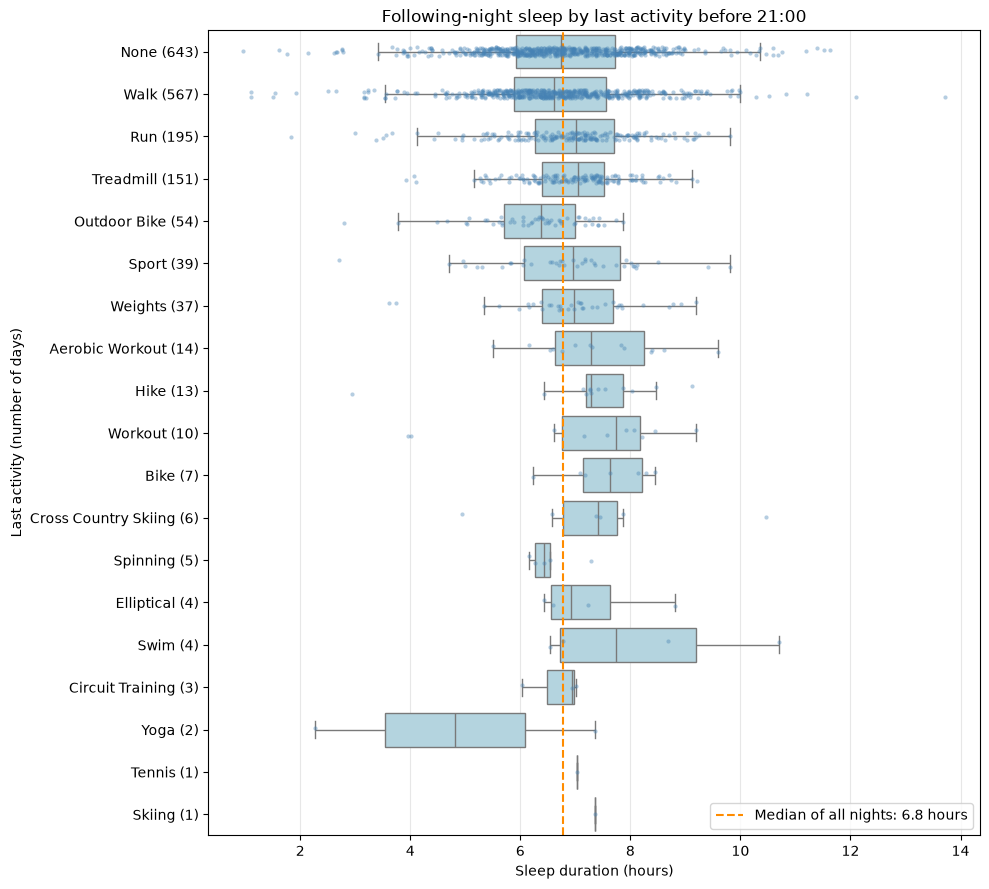

In [536]:
# Show the following night's sleep for each type of last activity.
activity_counts = model_data["last_activity"].value_counts()
activity_plot = model_data.assign(sleep_hours=model_data["next_sleep_minutes"] / 60)

fig, ax = plt.subplots(figsize=(10, 9))

sns.boxplot(
    data=activity_plot,
    x="sleep_hours",
    y="last_activity",
    order=activity_counts.index,
    color="lightblue",
    showfliers=False,
    ax=ax
)
sns.stripplot(
    data=activity_plot,
    x="sleep_hours",
    y="last_activity",
    order=activity_counts.index,
    color="steelblue",
    size=3,
    alpha=0.4,
    ax=ax
)

# Mark the median of all nights, so each activity can be compared with a typical night.
overall_median = activity_plot["sleep_hours"].median()
ax.axvline(
    overall_median,
    color="darkorange",
    linestyle="--",
    label=f"Median of all nights: {overall_median:.1f} hours"
)

# Show how many days each activity has next to its name.
ax.set_yticks(
    range(len(activity_counts)),
    [f"{activity} ({count})" for activity, count in activity_counts.items()]
)

ax.set_title("Following-night sleep by last activity before 21:00")
ax.set_xlabel("Sleep duration (hours)")
ax.set_ylabel("Last activity (number of days)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

From this we can see that values like yoga, tennis and skiing are rarely recorded and also that activities don't have that big of a difference on the person as I had expected. Now we give each activity type its own number. 0 means there was no session that day, and the other types are numbered from most to least common, so the most common one gets 1. The legend below shows which number belongs to which activity, so we can always translate the numbers back.

In [537]:
# Number the activity types from most to least common, keeping 0 for days without a session.
activity_types = model_data["last_activity"].value_counts().drop("None").index
activity_legend = {"None": 0} | {
    activity: number for number, activity in enumerate(activity_types, start=1)
}

model_data["last_activity"] = model_data["last_activity"].map(activity_legend)
activity_legend

{'None': 0,
 'Walk': 1,
 'Run': 2,
 'Treadmill': 3,
 'Outdoor Bike': 4,
 'Sport': 5,
 'Weights': 6,
 'Aerobic Workout': 7,
 'Hike': 8,
 'Workout': 9,
 'Bike': 10,
 'Cross Country Skiing': 11,
 'Spinning': 12,
 'Elliptical': 13,
 'Swim': 14,
 'Circuit Training': 15,
 'Yoga': 16,
 'Tennis': 17,
 'Skiing': 18}

Days without a session have no `min_since_last_activity`. Filling it with 0 would be wrong, because 0 means the session ended right at 21:00. Instead, we use the minutes from wake-up to 21:00: the participant has gone the whole day so far without a session. Since `last_activity` is 0 on those days, the model can still tell them apart from days with a real session. This only uses each day's own wake-up time, so nothing is learned from other rows.

In [538]:
# On days without a session, count the whole time from wake-up to 21:00.
minutes_awake = (
    combined_data["prediction_time"] - combined_data["wake_up_time"]
).dt.total_seconds() / 60
model_data["min_since_last_activity"] = model_data["min_since_last_activity"].fillna(minutes_awake)

# Confirm the model table has no missing values left.
model_data.isna().sum().sum()

np.int64(0)

From the table above we can also see that certain nights have sleep recorded between 2-4h per night, while those might actually be legitamate, I have suspisioun to believe those outliers might be caused by the fitbit band failing to work properly, Further analysis into nights that fall between 1-4h should be done.

In [539]:
# Count the following nights between 1 and 4 hours.
print(f"Number of sleep records between 1-4h {combined_data["next_sleep_minutes"].between(60, 240).sum()}")

Number of sleep records between 1-4h 58


From this count we can see that there are 58 outliers, which is not too many, another thing investigating is the sleep patterns, perhaps the fitbit band might count naps during the day as actual sleep, which wouldn't be useful. Also my suspisioun still stands that there might have been an issue with the wearable during the night. Next we will check for any patterns. To find patterns without deciding them myself, I will use k-means group the short nights by when they started and when they ended. Nights that start and end at similar times end up in the same group. Each dot is one night: when the sleep started goes from left to right, and when it ended goes from bottom to top.

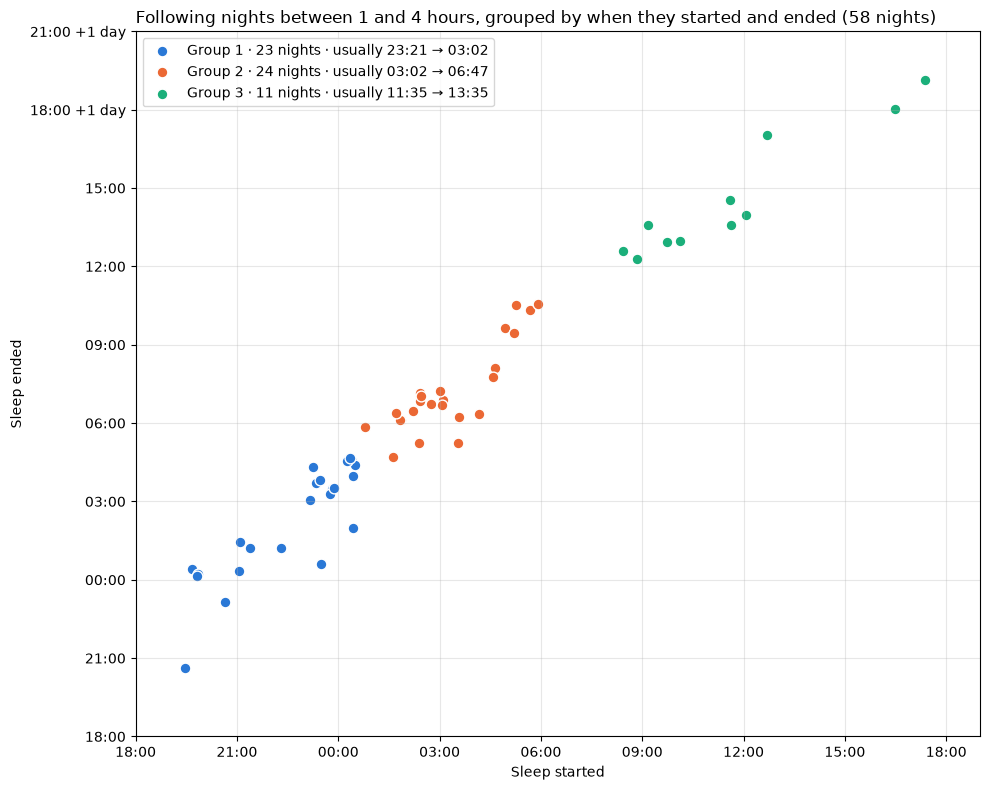

In [540]:
from sklearn.cluster import KMeans


def clock_hours(times):
    """Hours from midnight, with evening times (18:00 or later) counted as negative."""
    hours = times.dt.hour + times.dt.minute / 60
    return hours.where(hours < 18, hours - 24)


def clock_label(hour):
    return f"{int(hour % 24):02d}:{int(hour % 1 * 60):02d}"


# Date every night by the activity day before it, like the following night in combined_data.
nights = sleep_clean.assign(
    date=sleep_clean["sleep_date"] - pd.Timedelta(days=1),
    start_hour=clock_hours(sleep_clean["start_time"]),
    end_hour=clock_hours(sleep_clean["end_time"]),
)
# A sleep that runs past 18:00 ends on the next clock day.
nights["end_hour"] = nights["end_hour"].where(nights["end_hour"] >= nights["start_hour"], nights["end_hour"] + 24)

# Find the short following nights and add when they started and ended.
short_nights = (
    combined_data.loc[
        combined_data["next_sleep_minutes"].between(60, 240),
        ["participant_id", "date", "next_sleep_minutes"]
    ]
    .merge(nights[["participant_id", "date", "start_hour", "end_hour"]], on=["participant_id", "date"])
)

# Let k-means group the nights by start and end time, then number the groups by start time.
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
short_nights["group"] = kmeans.fit_predict(short_nights[["start_hour", "end_hour"]])
group_order = short_nights.groupby("group")["start_hour"].median().sort_values().index
short_nights["group"] = short_nights["group"].map({group: number for number, group in enumerate(group_order, start=1)})

group_colors = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}

fig, ax = plt.subplots(figsize=(10, 8))

for group, nights_in_group in short_nights.groupby("group"):
    typical_start = nights_in_group["start_hour"].median()
    typical_end = nights_in_group["end_hour"].median()

    # Every night in the group as one dot.
    ax.scatter(
        nights_in_group["start_hour"],
        nights_in_group["end_hour"],
        s=60,
        color=group_colors[group],
        edgecolor="white",
        label=(
            f"Group {group} · {len(nights_in_group)} nights · "
            f"usually {clock_label(typical_start)} → {clock_label(typical_end)}"
        )
    )

# Label both axes as clock times, from 18:00 to 18:00 the next day.
start_ticks = range(-6, 19, 3)
ax.set_xticks(start_ticks, [f"{hour % 24:02d}:00" for hour in start_ticks])
ax.set_xlim(-6, 19)

# Sleep can end the next evening, so those times are marked with +1 day.
end_ticks = range(-6, 22, 3)
ax.set_yticks(end_ticks, [f"{hour % 24:02d}:00" + (" +1 day" if hour >= 18 else "") for hour in end_ticks])
ax.set_ylim(-6, 21)

ax.set_title(f"Following nights between 1 and 4 hours, grouped by when they started and ended ({len(short_nights)} nights)", loc="left")
ax.set_xlabel("Sleep started")
ax.set_ylabel("Sleep ended")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

As you can see, there is some sort of relevance: the clusters are close, especially group 2. They have a lot of overlaps, whereas group 3 has a lot of differences.

- **Group 1** seems like it could be late naps. People just having late naps could also be people just having to wake up very early.
- **Group 2** actually seems to contain people that go to bed late, and/or nights where people went to bed late and woke up early. Maybe they had a reason to do that, so I would assume that their wearable were working fine, although this is not proper sleep, and you can't really predict these outcomes. I'm not really sure whether those are viable for our use case.
- **Group 3**: I imagine this group is going to be just people taking naps during the day. Perhaps this is not reliable, and we should exclude this group from our dataset.

For this use case, we're definitely dropping group 3 for this iteration, and we'll see how it works with the model.

In [541]:
# Find the participant and date of every night in group 3.
group_3_nights = short_nights.loc[short_nights["group"] == 3, ["participant_id", "date"]]
group_3_keys = group_3_nights.set_index(["participant_id", "date"]).index


def without_group_3(table):
    keys = table.set_index(["participant_id", "date"]).index
    return table.loc[~keys.isin(group_3_keys)].reset_index(drop=True)


# Remove them from both tables, so combined_data and model_data keep matching row for row.
rows_before = len(combined_data)
combined_data = without_group_3(combined_data)
model_data = without_group_3(model_data)

print(f"Removed {rows_before - len(combined_data)} group 3 nights; {len(combined_data):,} rows remain.")

Removed 11 group 3 nights; 1,745 rows remain.


In [542]:
model_data.describe()

,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,next_sleep_minutes
count,1745,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000,1745.000000
mean,2020-01-14 13:12:12.378223,8.207459,0.341156,406.297421,406.007736,10367.808023,1.042407,3.723209,5.545559,31.633811,1.573639,460.635817,408.406304
min,2019-11-01 00:00:00,0.233333,-11.916667,54.000000,54.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000,58.000000
25%,2019-12-10 00:00:00,6.633333,-0.950000,360.000000,369.000000,6075.000000,0.000000,0.000000,0.000000,0.000000,0.000000,256.416667,362.000000
50%,2020-01-14 00:00:00,7.633333,-0.166667,407.000000,407.333333,10169.000000,1.000000,0.000000,1.000000,16.000000,1.000000,411.416667,407.000000
75%,2020-02-17 00:00:00,9.000000,0.866667,456.000000,444.333333,14811.000000,2.000000,3.000000,8.000000,52.000000,2.000000,699.566667,457.000000
max,2020-03-31 00:00:00,20.633333,11.616667,823.000000,618.000000,38347.000000,7.000000,103.000000,95.000000,330.000000,18.000000,1239.000000,823.000000
std,NaN,2.537444,2.459831,83.767031,58.601347,6006.325540,1.073252,8.318189,9.276853,40.052939,2.307098,264.835599,79.571699


## 6. Train and test the model
For this first iteration, we keep things simple: all nights go into one dataset, and we split it by date for each participant, keeping the last 20% of their nights for testing. The model only gets the activity and sleep columns as inputs. `participant_id` and `date` are left out, and `next_sleep_minutes` is what it has to predict.

The three shares below can be changed for the whole comparison. The network uses 60% for training and 20% for validation. The other models use both of these parts for their final fit. All models and the baselines are tested on the same nights.

In [32]:
TRAIN_SHARE = 0.60
VALIDATION_SHARE = 0.20
TEST_SHARE = 0.20
if min(TRAIN_SHARE, VALIDATION_SHARE, TEST_SHARE) <= 0 or not np.isclose(
    TRAIN_SHARE + VALIDATION_SHARE + TEST_SHARE, 1
):
    raise ValueError("The three shares must be positive and add up to 1.")

ordered_nights = model_data.sort_values(["participant_id", "date"])
night_number = ordered_nights.groupby("participant_id").cumcount()
nights_per_person = ordered_nights.groupby("participant_id")["date"].transform("size")
training_end = (nights_per_person * TRAIN_SHARE).astype(int)
test_start = (nights_per_person * (1 - TEST_SHARE)).astype(int)
training_indices = ordered_nights.index[night_number < training_end]
validation_indices = ordered_nights.index[(night_number >= training_end) & (night_number < test_start)]
development_indices = ordered_nights.index[night_number < test_start]
test_indices = ordered_nights.index[night_number >= test_start]

inputs = model_data.drop(columns=["participant_id", "date", "next_sleep_minutes"])
target = model_data["next_sleep_minutes"]
inputs_train, inputs_test = inputs.loc[development_indices], inputs.loc[test_indices]
target_train, target_test = target.loc[development_indices], target.loc[test_indices]
print(f"Development nights: {len(inputs_train):,}; final test nights: {len(inputs_test):,}")

Development nights: 1,388; final test nights: 357


The first algorithm we would try is random forest. It splits the data into smaller groups and does not need the inputs to be scaled.

To see how far the predictions are from the truth, we report:

- **Average error (MAE)**: how many minutes the prediction is off on an average night.
- **RMSE**: also in minutes, but big misses count more, so it shows whether there are some very wrong predictions.
- **R²**: compares the model with always guessing the average sleep. 1 means perfect predictions, 0 means no better than guessing the average, and below 0 means worse.
- **Nights within 30 and 60 minutes**: the share of nights where the prediction was close to the truth.

RMSE is the main measure in the Research Document. We will also compare the models with two simple guesses: last night’s sleep and the average of the previous seven recorded nights.

In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

model_scores = {}

def sleep_scores(actual, predicted):
    errors = np.abs(np.asarray(actual) - np.asarray(predicted))
    return {
        "MAE (minutes)": mean_absolute_error(actual, predicted),
        "RMSE (minutes)": root_mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
        "Nights within 30 minutes": (errors <= 30).mean(),
        "Nights within 60 minutes": (errors <= 60).mean(),
    }

def report_scores(model, name):
    scores = sleep_scores(target_test, model.predict(inputs_test))
    model_scores[name] = scores
    print(f"MAE: {scores['MAE (minutes)']:.1f} minutes; RMSE: {scores['RMSE (minutes)']:.1f} minutes")
    print(f"R²: {scores['R²']:.3f}; within 60 minutes: {scores['Nights within 60 minutes']:.1%}")

### Sleep-history baselines
Last night’s duration and the average of the previous seven recorded nights provide two simple predictions without fitting a model. The seven-night history ends with the sleep observed that morning. It never includes the following night being predicted.

Seven recorded nights can span more than a week when nights are missing. At the start of a participant’s record, the average uses the available history. The chronological test period is checked to have seven recorded nights available for every prediction. During testing, a night that has already happened can be used in the next prediction.

In [34]:
sleep_history = sleep_clean.sort_values(["participant_id", "sleep_date"]).copy()
sleep_history["past_7_sleep_minutes"] = sleep_history.groupby("participant_id")["minutes_asleep"].transform(
    lambda nights: nights.rolling(7, min_periods=1).mean()
)
baseline_data = model_data[["participant_id", "date", "previous_sleep_minutes"]].join(
    sleep_history.set_index(["participant_id", "sleep_date"])["past_7_sleep_minutes"],
    on=["participant_id", "date"], validate="one_to_one",
)
for name, column in [("Last night", "previous_sleep_minutes"), ("Previous 7 recorded nights", "past_7_sleep_minutes")]:
    model_scores[name] = sleep_scores(target_test, baseline_data.loc[target_test.index, column])
pd.DataFrame({name: model_scores[name] for name in ["Last night", "Previous 7 recorded nights"]}).T.style.format({
    "MAE (minutes)": "{:.1f}", "RMSE (minutes)": "{:.1f}", "R²": "{:.3f}",
    "Nights within 30 minutes": "{:.1%}", "Nights within 60 minutes": "{:.1%}",
})

,MAE (minutes),RMSE (minutes),R²,Nights within 30 minutes,Nights within 60 minutes
Last night,76.6,105.0,-0.937,26.6%,53.5%
Previous 7 recorded nights,54.7,74.0,0.039,34.7%,68.6%


The seven-night average has an MAE of **54.7 minutes** and an RMSE of **74.0 minutes**. Predicting last night’s duration gives much larger errors: **76.6 minutes MAE** and **105.0 minutes RMSE**. The seven-night average is therefore the more demanding baseline on these test nights.

### Random forest

In [35]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
random_forest.fit(inputs_train, target_train)
report_scores(random_forest, "Random forest")

MAE: 55.6 minutes; RMSE: 74.4 minutes
R²: 0.026; within 60 minutes: 61.6%


I want to see how close the predictions are to the real sleep, both for the nights the model learned from and for new nights it has never seen.

Training nights: MAE 21 minutes, R² 0.87
Test nights:     MAE 56 minutes, R² 0.03


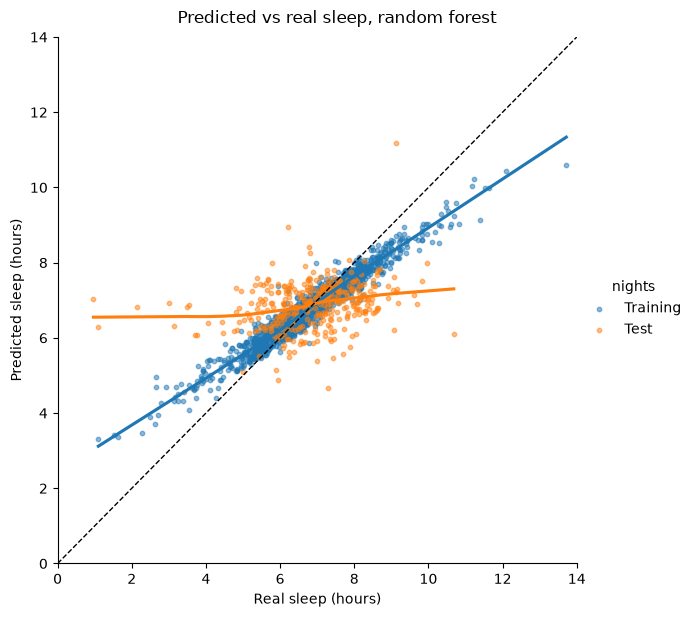

In [36]:
def compare_train_and_test(model, title):
    """Print the scores on the training and test nights, and plot predicted vs real sleep for both."""
    train_predictions = model.predict(inputs_train)
    test_predictions = model.predict(inputs_test)

    print(f"Training nights: MAE {mean_absolute_error(target_train, train_predictions):.0f} minutes, R² {r2_score(target_train, train_predictions):.2f}")
    print(f"Test nights:     MAE {mean_absolute_error(target_test, test_predictions):.0f} minutes, R² {r2_score(target_test, test_predictions):.2f}")

    # One table with every night, tagged as training or test.
    nights = pd.concat([
        pd.DataFrame({"real": target_train / 60, "predicted": train_predictions / 60, "nights": "Training"}),
        pd.DataFrame({"real": target_test / 60, "predicted": test_predictions / 60, "nights": "Test"}),
    ])

    plot = sns.lmplot(
        data=nights, x="real", y="predicted", hue="nights",
        lowess=True, height=6, scatter_kws={"s": 10, "alpha": 0.5},
    )
    plot.ax.plot([0, 14], [0, 14], color="black", linestyle="--", linewidth=1)
    plot.set(xlim=(0, 14), ylim=(0, 14))
    plot.set_axis_labels("Real sleep (hours)", "Predicted sleep (hours)")
    plot.fig.suptitle(title, y=1.02)
    plt.show()


compare_train_and_test(random_forest, "Predicted vs real sleep, random forest")

The training nights sit close to the line, but the test nights are spread out, and the scores are much better on the training nights than on the test nights. This suggests the model is overfitting: it fits the training nights much better than new ones. On the test nights it is slightly worse than the seven-night average. I want to see if messing around with the amount of leaves it has would do anything for the overfitting issue. But before perhaps I should check how many trees are actually being used and are useful for the model.

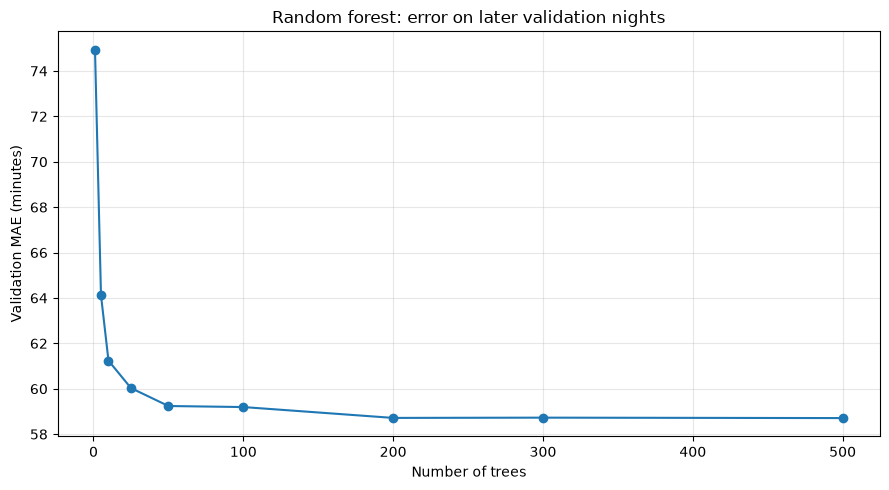

In [37]:
check_inputs, holdout_inputs = inputs.loc[training_indices], inputs.loc[validation_indices]
check_target, holdout_target = target.loc[training_indices], target.loc[validation_indices]

tree_counts = [1, 5, 10, 25, 50, 100, 200, 300, 500]
tree_errors = []
for n_trees in tree_counts:
    forest = RandomForestRegressor(n_estimators=n_trees, random_state=SEED, n_jobs=-1)
    forest.fit(check_inputs, check_target)
    tree_errors.append(mean_absolute_error(holdout_target, forest.predict(holdout_inputs)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tree_counts, tree_errors, marker="o")
ax.set(title="Random forest: error on later validation nights", xlabel="Number of trees",
       ylabel="Validation MAE (minutes)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The model seems to mostly flatline at about ~100 trees, so there is little benefit from using more than that in this run.

### Limiting the leaf size
By default, every tree keeps splitting the nights until each leaf holds just one night, so it can make a separate rule for every single training night. That is how it memorised them. With `min_samples_leaf` we can force every leaf to hold at least a certain number of nights, so every rule has to fit a group of nights instead of one. We will train it again.

Training nights: MAE 53 minutes, R² 0.18
Test nights:     MAE 53 minutes, R² 0.08


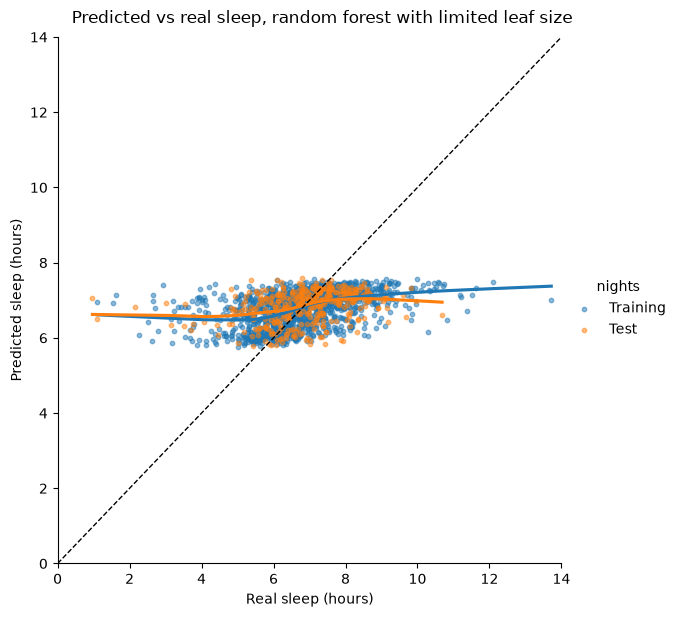

MAE: 53.1 minutes; RMSE: 72.2 minutes
R²: 0.084; within 60 minutes: 65.5%


In [38]:
# The same random forest, but every leaf has to hold at least 40 nights.
limited_forest = RandomForestRegressor(
    n_estimators=30, min_samples_leaf=40, random_state=SEED, n_jobs=-1
)
limited_forest.fit(inputs_train, target_train)

compare_train_and_test(limited_forest, "Predicted vs real sleep, random forest with limited leaf size")
report_scores(limited_forest, "Random forest, limited leaf size")

Now the overfitting issue seems much less obvious, even though the results are still not the best. Next I want to find out which features the model mainly relies on, so I know what changes I would need to make for the next iteration.

In [39]:
importance = limited_forest.feature_importances_
columns = inputs_train.columns

random_forest_cof = pd.Series(importance, columns)
random_forest_cof

wake_up_hour                 0.121451
previous_bedtime_hour        0.148697
previous_sleep_minutes       0.057046
avg_sleep_last_3_nights      0.449802
steps                        0.072649
session_count                0.004087
lightly_active_minutes       0.013766
moderately_active_minutes    0.027292
very_active_minutes          0.035206
last_activity                0.010394
min_since_last_activity      0.059609
dtype: float64

<Axes: >

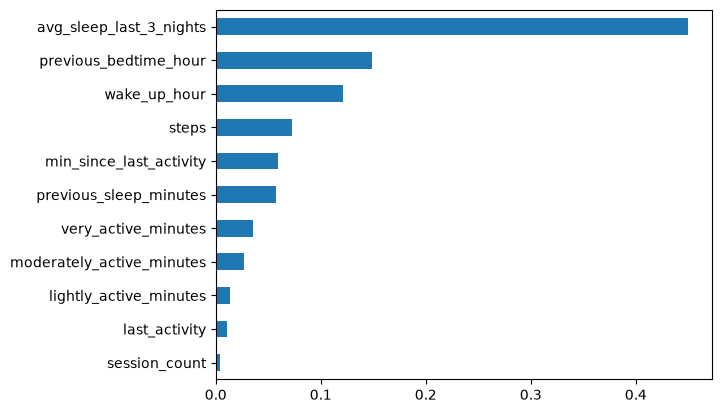

In [40]:
random_forest_cof.sort_values().plot.barh()

I can see that the avg_sleep feature is the one the model most relies on  but the others also seem to be taken into account. I want to see if that would still be the case if I were to shuffle them around.

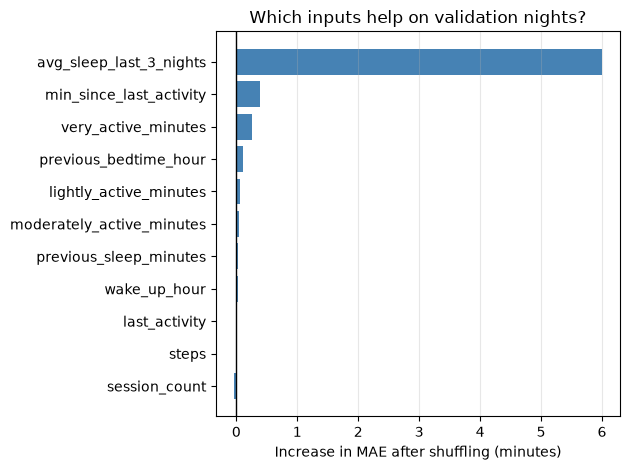

In [41]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance

validation_forest = clone(limited_forest).fit(check_inputs, check_target)
importance = permutation_importance(
    validation_forest, holdout_inputs, holdout_target,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEED, n_jobs=-1,
)
input_importance = pd.Series(importance.importances_mean, index=holdout_inputs.columns).sort_values()
fig, ax = plt.subplots()
ax.barh(input_importance.index, input_importance.values, color="steelblue")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Which inputs help on validation nights?", xlabel="Increase in MAE after shuffling (minutes)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Just as I thought, activity has little effect on this model in this run, it mainly uses sleep-related features. Perhaps in the future iteration it would be nice to add more on top of the features for stress and nutrition.

### Gradient boosting
The next model is gradient boosting. Like the random forest, it is made of many small trees, but instead of building them all separately and averaging them, it builds them one after another. Every new tree tries to fix the mistakes the previous trees made. Because each tree keeps correcting the last ones, it can also start memorising the training nights, so we keep the trees small and let each tree only correct a little.

Training nights: MAE 54 minutes, R² 0.15
Test nights:     MAE 53 minutes, R² 0.08


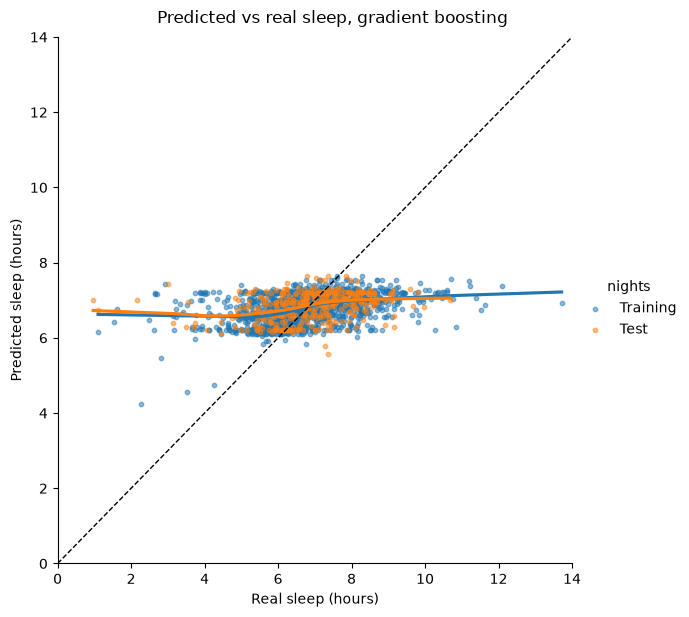

MAE: 53.3 minutes; RMSE: 72.2 minutes
R²: 0.084; within 60 minutes: 65.3%


In [42]:
from sklearn.ensemble import GradientBoostingRegressor

# Small trees that each correct a little of the previous mistakes.
gradient_boosting = GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.04, max_depth=1, random_state=SEED
)
gradient_boosting.fit(inputs_train, target_train)

compare_train_and_test(gradient_boosting, "Predicted vs real sleep, gradient boosting")
report_scores(gradient_boosting, "Gradient boosting")

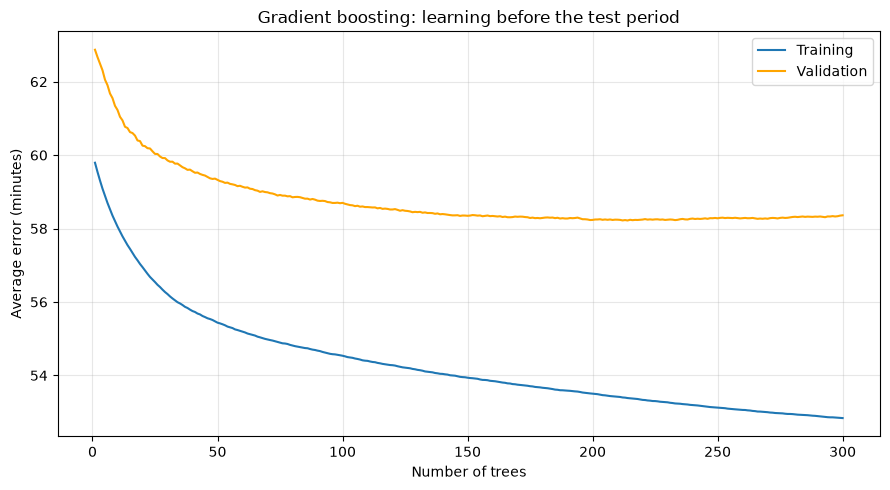

In [43]:
validation_boosting = clone(gradient_boosting).fit(check_inputs, check_target)
train_curve = [mean_absolute_error(check_target, p) for p in validation_boosting.staged_predict(check_inputs)]
validation_curve = [mean_absolute_error(holdout_target, p) for p in validation_boosting.staged_predict(holdout_inputs)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(train_curve) + 1), train_curve, label="Training")
ax.plot(range(1, len(validation_curve) + 1), validation_curve, color="orange", label="Validation")
ax.set(title="Gradient boosting: learning before the test period", xlabel="Number of trees",
       ylabel="Average error (minutes)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This chart shows how gradient boosting learns: it starts with a very rough guess and adds one small tree at a time, and every tree fixes a bit of the mistakes the earlier trees left. That is why the error drops quickly at the start and then flattens out: after a while, adding trees makes little difference on the validation nights. The lines end at 300 because that is how many trees we told it to build, and since the validation line is mostly flat by then, more trees seem unlikely to help much in this run.

### Linear regression
Now I will try linear regression, the simplest model. It gives every input a weight and adds them up, so more of an input always pushes the prediction the same way. This means it reads `last_activity` as an amount, as if Run (2) were twice as much as Walk (1), so we leave that input out for this model.

Training nights: MAE 57 minutes, R² 0.08
Test nights:     MAE 54 minutes, R² 0.07


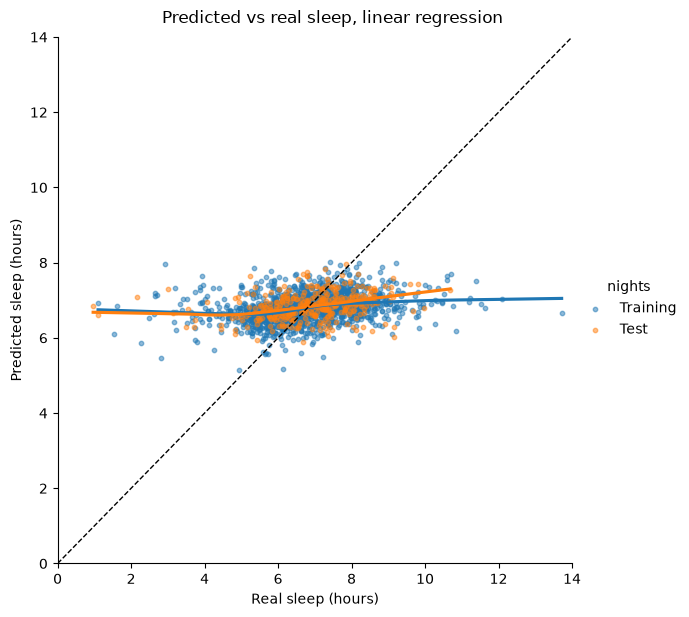

MAE: 54.1 minutes; RMSE: 72.6 minutes
R²: 0.074; within 60 minutes: 63.6%


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Linear regression would read the activity numbers as amounts, so it drops them first.
linear_regression = make_pipeline(
    ColumnTransformer([("drop_activity_type", "drop", ["last_activity"])], remainder="passthrough"),
    LinearRegression(),
)
linear_regression.fit(inputs_train, target_train)

compare_train_and_test(linear_regression, "Predicted vs real sleep, linear regression")
report_scores(linear_regression, "Linear regression")

With all inputs at once, linear regression cannot be drawn as one line. To see what it actually does, we also train it on our strongest input only, the average sleep of the last three nights.

Test nights: MAE 54 minutes, R² 0.07


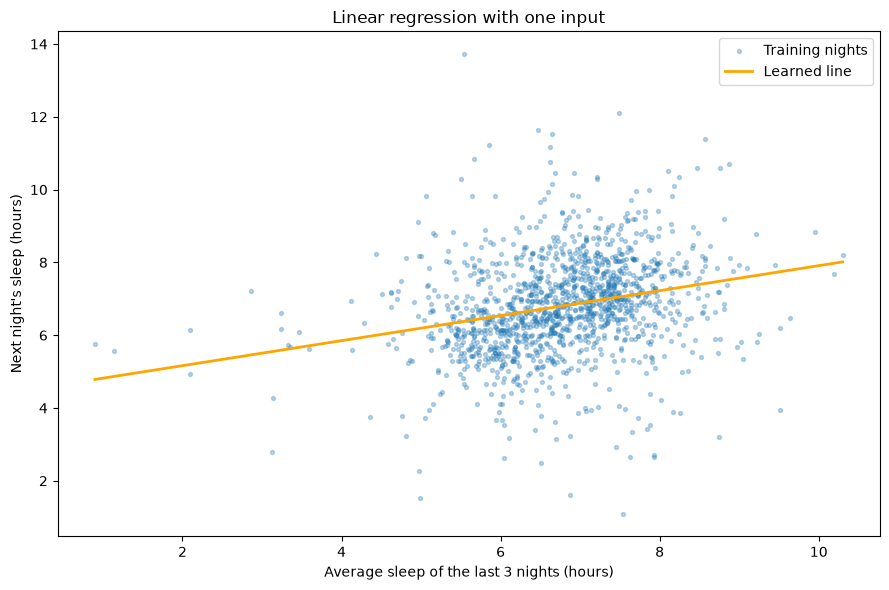

In [45]:
# Linear regression with only the strongest input, so it can be drawn as one line.
simple_regression = LinearRegression()
simple_regression.fit(inputs_train[["avg_sleep_last_3_nights"]], target_train)

start = simple_regression.intercept_
slope = simple_regression.coef_[0]

simple_predictions = simple_regression.predict(inputs_test[["avg_sleep_last_3_nights"]])
print(f"Test nights: MAE {mean_absolute_error(target_test, simple_predictions):.0f} minutes, R² {r2_score(target_test, simple_predictions):.2f}")

# Draw the training nights and the learned line, in hours.
line_x = np.linspace(inputs_train["avg_sleep_last_3_nights"].min(), inputs_train["avg_sleep_last_3_nights"].max(), 100)
line_y = start + slope * line_x

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(inputs_train["avg_sleep_last_3_nights"] / 60, target_train / 60, s=8, alpha=0.3, label="Training nights")
ax.plot(line_x / 60, line_y / 60, color="orange", linewidth=2, label="Learned line")
ax.set_title("Linear regression with one input")
ax.set_xlabel("Average sleep of the last 3 nights (hours)")
ax.set_ylabel("Next night's sleep (hours)")
ax.legend()
plt.tight_layout()
plt.show()

Even linear regression seems to get very low values in the R², perhaps the issue might be in the fact that this is a rather hard to predict topic as there are many unknown variables, like alarms, waking up for work etc. Next I will try a MLP model, to see if maybe it can catch on things the other models can't.

### Neural Network
Now I will try out an MLP model, to see whether this helps with sleep prediction. Perhaps it scores better than the rest models as it allows for more flexibility in the models. However, my dataset isn't that big, so it's very likely to run into an overfiting issue.

In [46]:
import logging
import lightning
import torch

from torch import nn
from torch.utils.data import TensorDataset
from lightning import LightningDataModule, LightningModule, Trainer
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from sklearn.preprocessing import OneHotEncoder, StandardScaler

logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
lightning.seed_everything(SEED, verbose=False)
torch.set_num_threads(1)

The network uses the three parts from the chronological split above:

- **Training:** the earliest 60% of each participant’s prepared nights.
- **Validation:** the next 20%, used to keep the best version of the network.
- **Test:** the final 20%, shared with the other models.

The three values in the shared split above can be changed to try a different division. `0.60` means 60% of all prepared nights, and the values must add up to 1.

Scaling is learned only from the network’s training nights.

In [47]:
network_inputs_train = inputs.loc[training_indices]
network_inputs_val = inputs.loc[validation_indices]
network_inputs_test = inputs_test.copy()
network_target_train = target.loc[training_indices]
network_target_val = target.loc[validation_indices]
network_target_test = target_test.copy()
print(f"Training: {len(network_inputs_train):,}; validation: {len(network_inputs_val):,}; test: {len(network_inputs_test):,}")

Training: 1,039; validation: 349; test: 357


Now we will prepare the input values for the network. A day might have 10,000 steps but only 1 exercise session. Scaling brings these very different numerical ranges closer together, which helps training.

Activity types become separate yes/no columns, since run being numbered 2 does not mean twice as much activity as Walk numbered 1. Sleep duration is scaled too, then converted back to minutes after prediction. The averages and scales used here come only from the network's training nights.

In [48]:
numeric_columns = inputs.columns.drop("last_activity")
network_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("activity", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["last_activity"]),
])
network_preprocessor.fit(network_inputs_train)
target_scaler = StandardScaler().fit(network_target_train.to_numpy().reshape(-1, 1))

Now we will pair each night's inputs with the sleep duration it should predict. PyTorch's **TensorDataset** keeps these pairs together. The **DataModule** feeds them to the network a few nights at a time, in groups of 32, instead of all at once.

In [49]:
def network_dataset(features, targets):
    scaled_inputs = network_preprocessor.transform(features)
    scaled_target = target_scaler.transform(targets.to_numpy().reshape(-1, 1)).ravel()
    return TensorDataset(
        torch.tensor(scaled_inputs, dtype=torch.float32),
        torch.tensor(scaled_target, dtype=torch.float32),
    )

network_train = network_dataset(network_inputs_train, network_target_train)
network_val = network_dataset(network_inputs_val, network_target_val)
network_test = network_dataset(network_inputs_test, network_target_test)
datamodule = LightningDataModule.from_datasets(
    network_train, network_val, network_test, batch_size=32, num_workers=0
)

Now we will define the network. We will start off with 64 nodes, but the number can be changed bellow, with one hidden layer.

In [50]:
class RegressionModel(LightningModule):
    def __init__(self, num_features):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )
        self.criterion = nn.MSELoss()

    def forward(self, features):
        return self.model(features).view(-1)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=0.001)

    def training_step(self, batch):
        features, targets = batch
        loss = self.criterion(self(features), targets)
        self.log("train_loss", loss, on_step=False, on_epoch=True, batch_size=len(targets))
        return loss

    def validation_step(self, batch):
        features, targets = batch
        loss = self.criterion(self(features), targets)
        self.log("val_loss", loss, on_step=False, on_epoch=True, batch_size=len(targets))

    def predict_step(self, batch):
        features, _ = batch
        return self(features)

model = RegressionModel(num_features=network_train.tensors[0].shape[1])

Now we will train it. After each epoch, the network will be checked on the validation nights to see whether its predictions are still improving, if not the training will be stopped earlier. I will also save the checkpoint, which is the best version of the network epocs lifespan.

In [51]:
logger = CSVLogger(save_dir="lightning_logs", name="sleep_network")
stop = EarlyStopping(monitor="val_loss", mode="min", patience=20)
best = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)
trainer = Trainer(
    logger=logger, max_epochs=200, accelerator="cpu", deterministic=True,
    callbacks=[stop, best], log_every_n_steps=10,
    enable_progress_bar=False, enable_model_summary=False,
)
trainer.fit(model, datamodule=datamodule)

/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.


/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `D

I want to visualize the training and validation during the training as I want to see if the model overfits this dataset, which I have very big suspisioun that it might do.

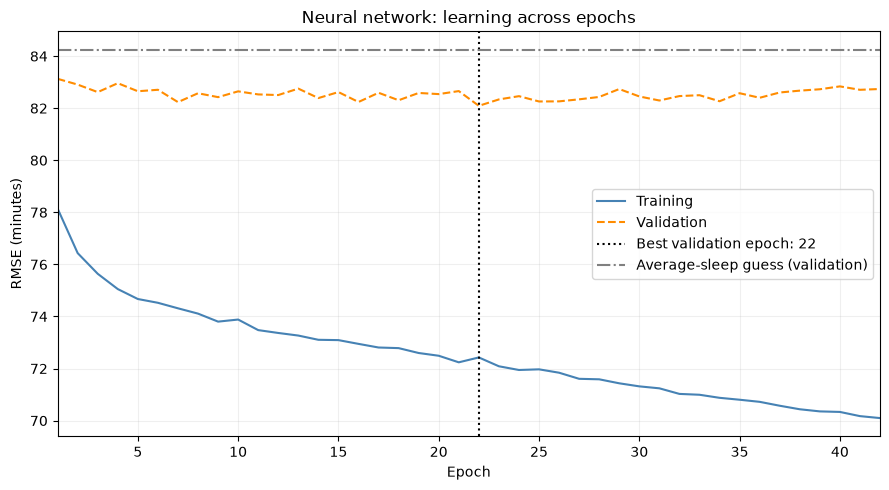

Training stopped after 42 epochs; the saved network is from epoch 22.
Training error changed from 78.1 to 70.1 minutes.
Validation error changed from 83.1 to 82.7 minutes.


In [52]:
metrics = pd.read_csv(Path(logger.log_dir) / "metrics.csv")
losses = metrics.groupby("epoch")[["train_loss", "val_loss"]].mean().dropna()
epochs = losses.index.to_numpy() + 1
target_scale = target_scaler.scale_[0]
best_epoch = int(losses["val_loss"].idxmin()) + 1
baseline_minutes = network_target_train.mean()
baseline_val_rmse = root_mean_squared_error(
    network_target_val, np.full(len(network_target_val), baseline_minutes)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    epochs, np.sqrt(losses["train_loss"]) * target_scale,
    label="Training", color="steelblue",
)
ax.plot(
    epochs, np.sqrt(losses["val_loss"]) * target_scale,
    label="Validation", color="darkorange", linestyle="--",
)
ax.axvline(
    best_epoch, color="black", linestyle=":",
    label=f"Best validation epoch: {best_epoch}",
)
ax.axhline(
    baseline_val_rmse, color="grey", linestyle="-.",
    label="Average-sleep guess (validation)",
)
ax.set(
    title="Neural network: learning across epochs",
    xlabel="Epoch", ylabel="RMSE (minutes)",
)
ax.set_xlim(1, epochs[-1])
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
print(
    f"Training stopped after {len(losses)} epochs; "
    f"the saved network is from epoch {best_epoch}."
)
training_rmse = np.sqrt(losses["train_loss"]) * target_scale
validation_rmse = np.sqrt(losses["val_loss"]) * target_scale
print(
    f"Training error changed from {training_rmse.iloc[0]:.1f} "
    f"to {training_rmse.iloc[-1]:.1f} minutes."
)
print(
    f"Validation error changed from {validation_rmse.iloc[0]:.1f} "
    f"to {validation_rmse.iloc[-1]:.1f} minutes."
)

My suspicion of overfitting seems to be right. Training error keeps falling from about 78 to 70 minutes, while validation error starts at 83.1 minutes and finishes at 82.7. The gap keeps growing, so the extra training is not helping on the validation nights.

The best validation result is at epoch 22. More epochs do not necessarily mean a better result.


In [53]:
output = trainer.predict(model, dataloaders=datamodule.test_dataloader(), ckpt_path="best")
scaled_predictions = torch.cat(output).numpy().reshape(-1, 1)
network_predictions = target_scaler.inverse_transform(scaled_predictions).ravel()
model_scores["Neural network"] = sleep_scores(network_target_test, network_predictions)
network_comparison = pd.DataFrame({
    name: model_scores[name] for name in ["Last night", "Previous 7 recorded nights", "Neural network"]
}).T
network_comparison.style.format({
    "MAE (minutes)": "{:.1f}", "RMSE (minutes)": "{:.1f}", "R²": "{:.3f}",
    "Nights within 30 minutes": "{:.1%}", "Nights within 60 minutes": "{:.1%}",
})

/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/opt/anaconda3/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


,MAE (minutes),RMSE (minutes),R²,Nights within 30 minutes,Nights within 60 minutes
Last night,76.6,105.0,-0.937,26.6%,53.5%
Previous 7 recorded nights,54.7,74.0,0.039,34.7%,68.6%
Neural network,52.7,71.1,0.112,35.9%,66.7%


The network gets an average test error of ~52.7 minutes, compared with ~54.7 minutes for guessing the seven-night average. That is an improvement of about 2 minutes, but the R² is still only 0.112. There is some improvement in this run, although the network still explains little of the differences between nights. I want to see what % of the nights were estimated within an hour of their actual duration.

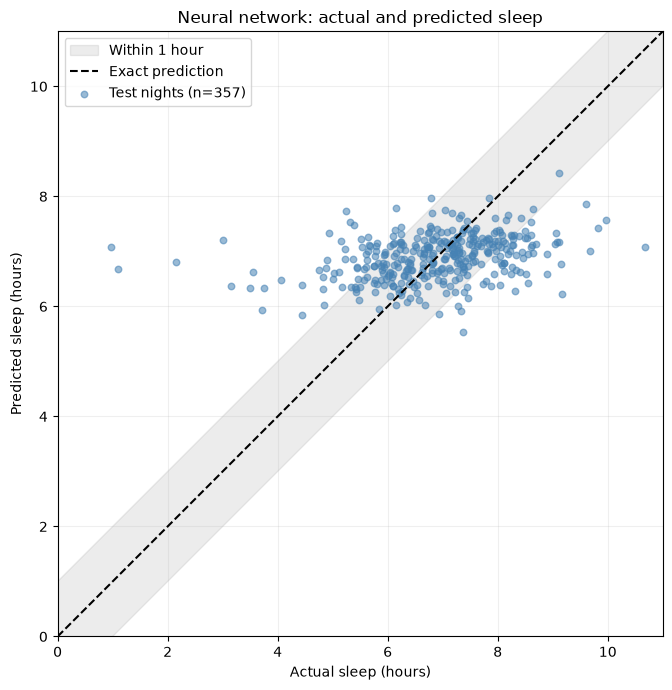

Predictions within one hour: 66.7% of the test nights.
Actual sleep ranges from 1.0 to 10.7 hours.
Predictions range from 5.5 to 8.4 hours.


In [54]:
network_results = pd.DataFrame({
    "actual_hours": network_target_test / 60,
    "predicted_hours": network_predictions / 60,
})
limit = np.ceil(network_results.to_numpy().max())
reference = np.linspace(0, limit, 100)

fig, ax = plt.subplots(figsize=(7, 7))
ax.fill_between(
    reference, reference - 1, reference + 1,
    color="grey", alpha=0.15, label="Within 1 hour",
)
ax.plot(reference, reference, color="black", linestyle="--", label="Exact prediction")
ax.scatter(
    network_results["actual_hours"], network_results["predicted_hours"],
    s=22, alpha=0.55, color="steelblue", label=f"Test nights (n={len(network_target_test)})",
)
ax.set(
    title="Neural network: actual and predicted sleep",
    xlabel="Actual sleep (hours)", ylabel="Predicted sleep (hours)",
    xlim=(0, limit), ylim=(0, limit),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
errors = np.abs(network_target_test.to_numpy() - network_predictions)
print(f"Predictions within one hour: {(errors <= 60).mean():.1%} of the test nights.")
print(
    f"Actual sleep ranges from {network_results['actual_hours'].min():.1f} "
    f"to {network_results['actual_hours'].max():.1f} hours."
)
print(
    f"Predictions range from {network_results['predicted_hours'].min():.1f} "
    f"to {network_results['predicted_hours'].max():.1f} hours."
)

Predictions stay between 5.5 and 8.4 hours, even though the actual sleep ranges from 1.0 to 10.7 hours. The network often predicts too much sleep for short nights and too little for long nights. It has mainly learned what an ordinary night looks like and struggles with the unusual ones.

About 66.7% of predictions are within one hour. Together with the narrow range of guesses, this suggests that the average error hides some large misses. The network is not predicting the variation between nights particularly well. Perhaps adding an extra feature containing the day of week for my future run might solve this issue, as it would actually give some context to the model, it might learn that on weekends people sleep more.

### Comparing the models
These are each model's final test results. I also want to compare how often they get within 30 and 60 minutes of the actual sleep, since an average error alone can hide how many nights were reasonably close.

All models and both baselines use the same test nights: the last 20% of each participant’s prepared records. The network uses validation for early stopping, so it trains on fewer nights than the other models’ final fits.

In [55]:
network_errors = np.abs(network_target_test.to_numpy() - network_predictions)
model_scores["Neural network"].update({
    "Nights within 30 minutes": (network_errors <= 30).mean(),
    "Nights within 60 minutes": (network_errors <= 60).mean(),
})

score_columns = [
    "MAE (minutes)", "RMSE (minutes)", "R²",
    "Nights within 30 minutes", "Nights within 60 minutes",
]
comparison = pd.DataFrame(model_scores).T[score_columns].copy()
comparison["Test nights"] = [
    len(network_target_test) if name == "Neural network" else len(target_test)
    for name in comparison.index
]

if set(network_inputs_test.index) == set(inputs_test.index):
    print(f"Current run: all models used the same {len(target_test):,} test nights.")
else:
    print("The models have different test nights; each score is from its own test set.")

comparison.style.format({
    "MAE (minutes)": "{:.1f}",
    "RMSE (minutes)": "{:.1f}",
    "R²": "{:.3f}",
    "Nights within 30 minutes": "{:.1%}",
    "Nights within 60 minutes": "{:.1%}",
    "Test nights": "{:,.0f}",
})

Current run: all models used the same 357 test nights.


,MAE (minutes),RMSE (minutes),R²,Nights within 30 minutes,Nights within 60 minutes,Test nights
Last night,76.6,105.0,-0.937,26.6%,53.5%,357
Previous 7 recorded nights,54.7,74.0,0.039,34.7%,68.6%,357
Random forest,55.6,74.4,0.026,34.7%,61.6%,357
"Random forest, limited leaf size",53.1,72.2,0.084,39.5%,65.5%,357
Gradient boosting,53.3,72.2,0.084,38.9%,65.3%,357
Linear regression,54.1,72.6,0.074,35.3%,63.6%,357
Neural network,52.7,71.1,0.112,35.9%,66.7%,357


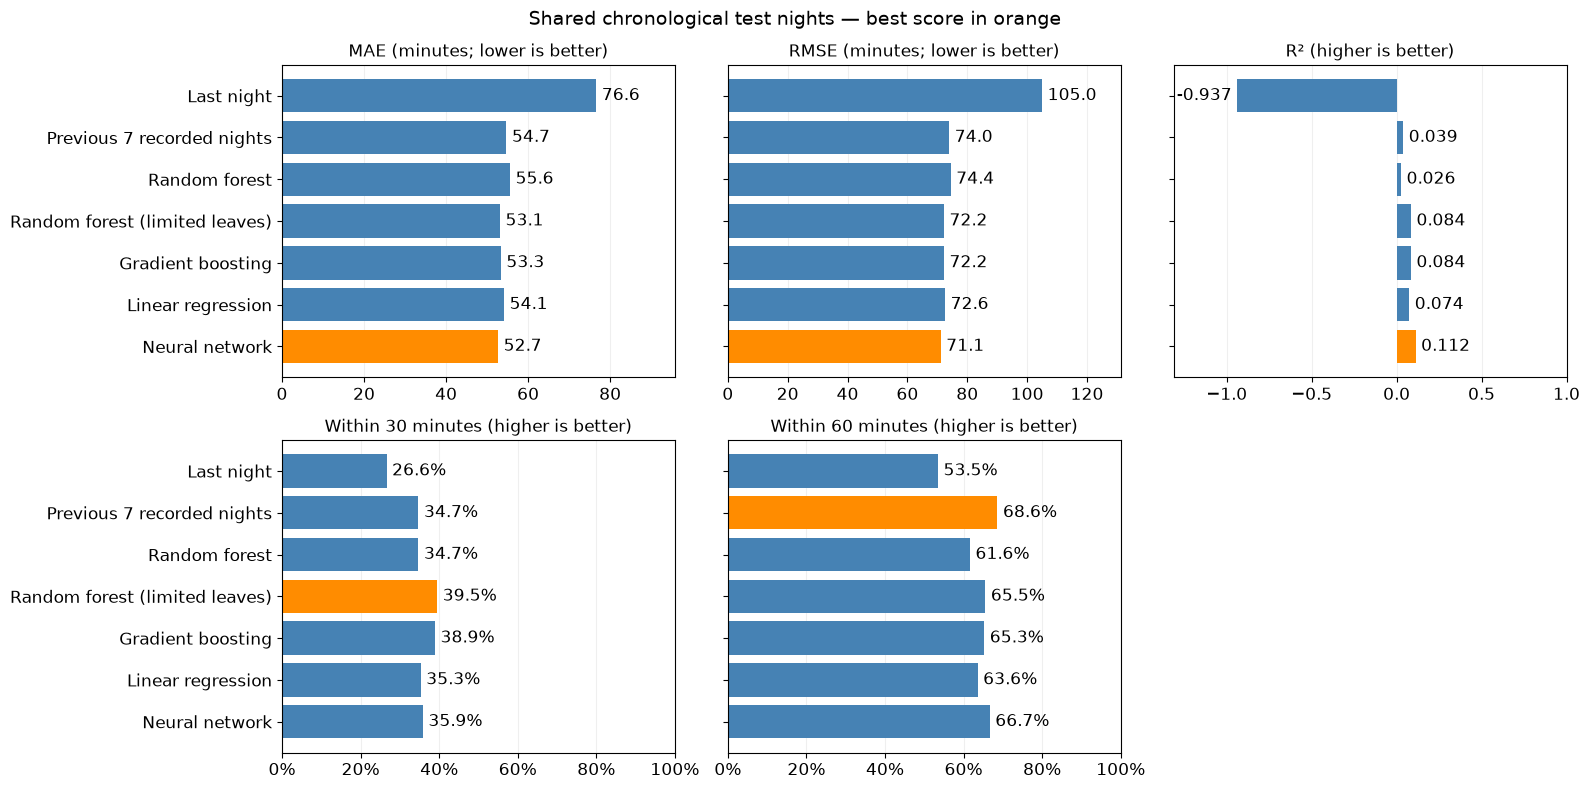

In [56]:
from matplotlib.ticker import PercentFormatter

chart_titles = [
    "MAE (minutes; lower is better)",
    "RMSE (minutes; lower is better)",
    "R² (higher is better)",
    "Within 30 minutes (higher is better)",
    "Within 60 minutes (higher is better)",
]
model_labels = [
    name.replace("Random forest, limited leaf size", "Random forest (limited leaves)")
    for name in comparison.index
]
positions = np.arange(len(comparison))
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)

for ax, score, title in zip(axes.flat, score_columns, chart_titles):
    values = comparison[score]
    lower_is_better = score in ["MAE (minutes)", "RMSE (minutes)"]
    best_value = values.min() if lower_is_better else values.max()
    colors = [
        "darkorange" if np.isclose(value, best_value) else "steelblue"
        for value in values
    ]
    ax.barh(positions, values, color=colors)
    ax.set_yticks(positions, model_labels, fontsize=12)
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    if score.startswith("Nights within"):
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    elif score == "R²":
        ax.set_xlim(min(0, values.min() * 1.4), 1)
    else:
        ax.set_xlim(0, values.max() * 1.25)

    for position, value in enumerate(values):
        if score.startswith("Nights within"):
            label = f"{value:.1%}"
        elif score == "R²":
            label = f"{value:.3f}"
        else:
            label = f"{value:.1f}"
        ax.annotate(
            label, (value, position),
            xytext=(4 if value >= 0 else -4, 0), textcoords="offset points",
            va="center", ha="left" if value >= 0 else "right", fontsize=12,
        )

axes[0, 0].invert_yaxis()
axes[1, 2].set_visible(False)
fig.suptitle("Shared chronological test nights — best score in orange", fontsize=14)
plt.tight_layout()
plt.show()

The neural network has the lowest average error at 52.7 minutes, while the seven-night average has the highest share within one hour at 68.6%. The network gets 66.7% within one hour. On these 357 test nights, that is 238 close predictions for the network.

The network also has the lowest RMSE, although it is close to the limited forest and gradient boosting. The model that wins on MAE and RMSE would be the neural network, but the limited forest takes the lead within 30 minutes and the seven-night average within 60 minutes.

## Conclusion

During the first iteration, the models reached similar results. Roughly 2/3 of their test predictions were within one hour of the actual sleep duration. The low R² scores show that the current models still explain little of the variation in sleep duration. Using a more complex model only led to a small improvement over the seven-night average.

For the next iteration, I want to add `weekday` as the specific day of the week, from Monday (1) to Sunday (7). This could help the models pick up differences in people's routines across individual days.

I also want to use features like stress, meal count, fluid intake, alcohol consumption, and the participant's recorded gender. These would add information about daily habits and personal differences beyond activity and sleep history.


# Iteration 2

## Data Exploration, Preparation and Modelling

### What changes in this iteration?

Do weekday, stress, meals, drinks, and recorded gender improve the sleep predictions?

The dataset, sleep-duration target, and 21:00 prediction time stay the same. The prepared sleep and activity data from iteration 1 can be reused, with the new inputs added alongside them. Iteration 1 remains the reference for comparison.

### 1. Check the additional data

| Input | Source |
| --- | --- |
| `weekday` — Monday (1) to Sunday (7) | Prediction date |
| Stress | Wellness reports |
| Meal count | Daily reports |
| Fluid intake | Daily reports: glasses of fluid |
| Alcohol consumption | Daily reports |
| Recorded gender | Participant overview |

The reports need checking for missing values and submission times. A report is only usable if it was available by 21:00. Meal counts describe how often people ate, rather than what they ate.

If missing reports reduce the available nights, both feature sets need comparing on those same nights to separate the effect of new inputs from the effect of changing the data.

### 2. Explore the wellness reports

To begin with, I want to start by first exploring the wellness dataset to see what features we can use from it.

In [566]:
wellness_example = pd.read_csv(participant_folders[0] / "pmsys/wellness.csv")
wellness_example.head(10)

,effective_time_frame,fatigue,mood,readiness,sleep_duration_h,sleep_quality,soreness,soreness_area,stress
0,2019-11-01T08:31:40.751Z,2,3,5,6,3,2,[12921003],3
1,2019-11-02T10:00:01.229Z,2,3,6,6,3,2,[12921003],3
2,2019-11-03T14:28:03.263Z,3,3,8,6,3,3,[],3
3,2019-11-04T07:05:28.429Z,3,3,8,6,3,3,[],3
4,2019-11-05T06:13:35.998Z,3,3,8,5,3,3,[],3
5,2019-11-06T07:13:02.320Z,3,3,5,5,3,2,"[48979004, 32696007]",3
6,2019-11-07T06:39:25.426Z,3,3,7,5,3,3,[],3
7,2019-11-08T09:05:09.558Z,3,3,7,6,3,3,[],3
8,2019-11-09T08:00:27.364Z,3,3,8,6,3,3,[],3
9,2019-11-10T20:38:08.787Z,3,3,7,6,3,3,[],3


Each row has a report date and time and several self-reported scores. I find fatigue, mood, sleep quality from the previous night, and stress the most interesting, and I will add them as features. First, I need to check whether we have values for the participants' already recorded nights.

These four scores use a 1–5 scale, with 5 being the highest, 3 the middle, and 1 the lowest.

In [567]:
wellness_features = ["stress", "fatigue", "mood", "sleep_quality"]

wellness_tables = []
for folder in participant_folders:
    records = pd.read_csv(folder / "pmsys/wellness.csv")
    records["participant_id"] = folder.name
    wellness_tables.append(records)

wellness = pd.concat(wellness_tables, ignore_index=True)
wellness["reported_at"] = pd.to_datetime(
    wellness["effective_time_frame"], utc=True, errors="coerce"
)

print(f"Reports: {len(wellness):,}; participants: {wellness['participant_id'].nunique()}")
print(f"Exact duplicate rows: {wellness.duplicated().sum()}")
print(f"Unreadable report timestamps: {wellness['reported_at'].isna().sum()}")

wellness_summary = pd.DataFrame({
    "Missing values": wellness[wellness_features].isna().sum(),
    "Outside 1–5": (
        wellness[wellness_features].lt(1) | wellness[wellness_features].gt(5)
    ).sum(),
    "Minimum": wellness[wellness_features].min(),
    "Maximum": wellness[wellness_features].max(),
})
wellness_summary

Reports: 1,747; participants: 16
Exact duplicate rows: 0
Unreadable report timestamps: 0


,Missing values,Outside 1–5,Minimum,Maximum
stress,0,4,0,5
fatigue,0,2,0,5
mood,0,3,0,5
sleep_quality,0,2,0,5


The wellness files contain 1,747 reports across 16 participants, with no exact duplicate rows or unreadable timestamps. None of the four selected fields is empty, but each contains a few zeros outside the [documented 1–5 scale](https://datasets.simula.no/pmdata/). Those values need resolving before modelling.

This does not yet tell us how many reports match the existing prediction days.

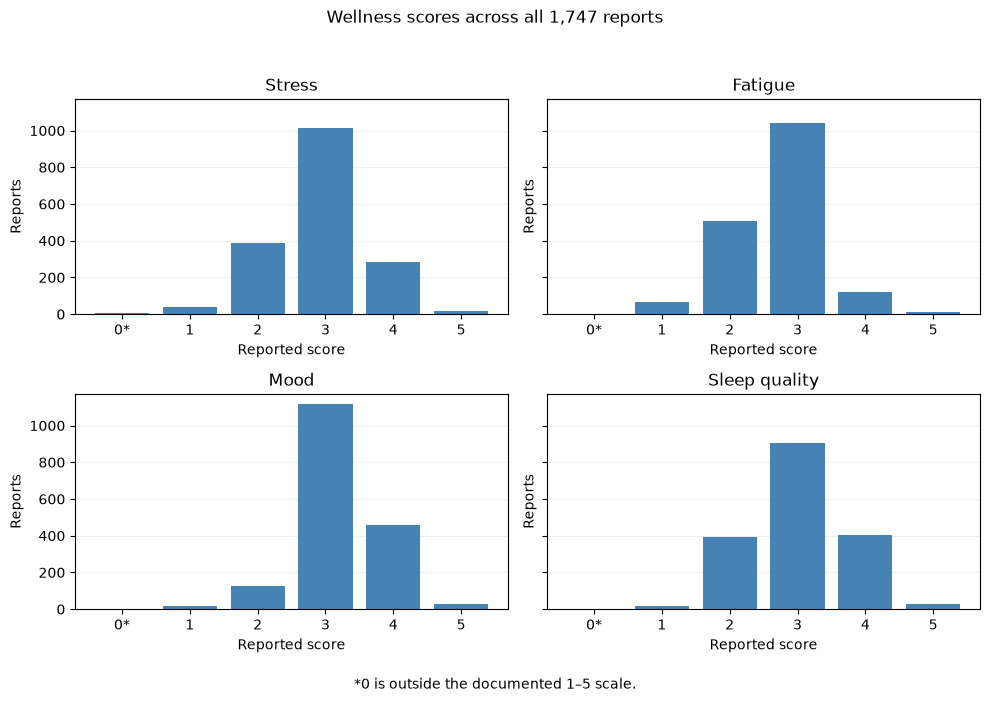

In [568]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)

for ax, feature in zip(axes.flat, wellness_features):
    counts = wellness[feature].value_counts().reindex(range(6), fill_value=0)
    ax.bar(counts.index, counts.values, color="steelblue")
    ax.set_title(feature.replace("_", " ").capitalize())
    ax.set_xticks(range(6), ["0*", "1", "2", "3", "4", "5"])
    ax.set_xlabel("Reported score")
    ax.set_ylabel("Reports")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("Wellness scores across all 1,747 reports")
fig.text(0.5, 0.01, "*0 is outside the documented 1–5 scale.", ha="center")
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

Score 3 is the most common response for all four measurements. Mood is mostly 3 or 4, while fatigue is mostly 2 or 3. Extreme scores seem to be rare. Next, I want to find out how many prediction nights have corresponding wellness reports. `model_data` contains the nights used in iteration 1, including their sleep targets. Matching by participant and date shows which of those nights have a wellness report.

In [569]:
wellness_report_days = (
    wellness.assign(date=wellness["reported_at"].dt.tz_localize(None).dt.normalize())
    .groupby(["participant_id", "date"])
    .size()
    .rename("report_count")
    .reset_index()
)

wellness_overlap = model_data[[
    "participant_id", "date", "next_sleep_minutes"
]].merge(
    wellness_report_days,
    on=["participant_id", "date"],
    how="left",
    validate="one_to_one",
)
wellness_overlap["has_report"] = wellness_overlap["report_count"].notna()
wellness_overlap["multiple_reports"] = wellness_overlap["report_count"].gt(1)

wellness_coverage = wellness_overlap.groupby("participant_id").agg(**{
    "Prediction nights": ("date", "size"),
    "With same-date report": ("has_report", "sum"),
    "With multiple reports": ("multiple_reports", "sum"),
})
wellness_coverage["Without same-date report"] = (
    wellness_coverage["Prediction nights"] - wellness_coverage["With same-date report"]
)
wellness_coverage = wellness_coverage[[
    "Prediction nights", "With same-date report",
    "Without same-date report", "With multiple reports",
]]
wellness_coverage.loc["Total"] = wellness_coverage.sum()
wellness_coverage

,Prediction nights,With same-date report,Without same-date report,With multiple reports
participant_id,,,,
p01,148,136,12,0
p02,136,93,43,0
p03,56,38,18,1
p04,139,133,6,1
p05,107,97,10,2
p06,147,144,3,0
p07,136,123,13,1
p08,127,90,37,1
p09,117,87,30,0


Of the 1,745 prediction nights from iteration 1, 1,415 have at least one report on the same UTC date and 330 have none. Ten prediction days have more than one report, so further checks of those specific dates should be done to figure out what happened.

These are possible matches, not a final count of usable nights.

### 4. Where are the missing reports?

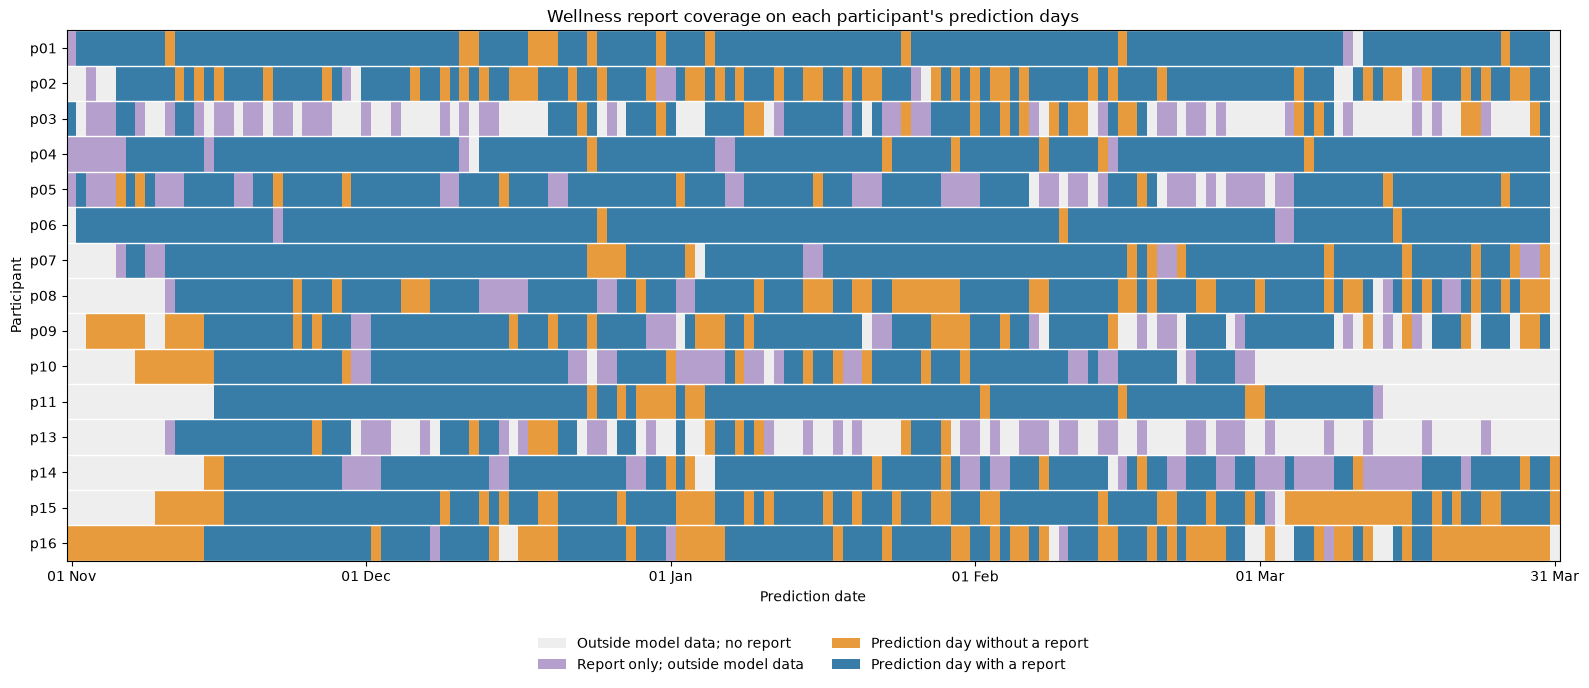

In [570]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

calendar_dates = pd.date_range(model_data["date"].min(), model_data["date"].max())
calendar_participants = sorted(model_data["participant_id"].unique())

model_calendar = pd.crosstab(model_data["participant_id"], model_data["date"]).reindex(
    index=calendar_participants, columns=calendar_dates, fill_value=0
).gt(0)
report_calendar = pd.crosstab(
    wellness_report_days["participant_id"], wellness_report_days["date"]
).reindex(index=calendar_participants, columns=calendar_dates, fill_value=0).gt(0)
calendar_status = model_calendar.astype(int) * 2 + report_calendar.astype(int)

status_labels = [
    "Outside model data; no report",
    "Report only; outside model data",
    "Prediction day without a report",
    "Prediction day with a report",
]
status_colors = ["#eeeeee", "#b5a0cd", "#e89b3c", "#377da8"]

fig, ax = plt.subplots(figsize=(16, 7))
ax.imshow(
    calendar_status, aspect="auto", interpolation="nearest",
    cmap=ListedColormap(status_colors), vmin=-0.5, vmax=3.5,
)
ax.set_yticks(range(len(calendar_participants)), calendar_participants)
month_ticks = [i for i, date in enumerate(calendar_dates) if date.day == 1]
date_ticks = sorted(set([0, *month_ticks, len(calendar_dates) - 1]))
ax.set_xticks(date_ticks, [calendar_dates[i].strftime("%d %b") for i in date_ticks])
ax.set_yticks(np.arange(-0.5, len(calendar_participants)), minor=True)
ax.grid(which="minor", axis="y", color="white", linewidth=1)
ax.tick_params(which="minor", left=False)
ax.set_title("Wellness report coverage on each participant's prediction days")
ax.set_xlabel("Prediction date")
ax.set_ylabel("Participant")
ax.legend(
    handles=[Patch(facecolor=color, label=label) for color, label in zip(status_colors, status_labels)],
    loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False,
)
plt.tight_layout()
plt.show()

The gaps differ across participants, but we can clearly see that not every recorded night in `model_data` has a corresponding entry in the wellness data. This means that further data cleaning should be done, which will leave us with even less usable data for our models. Before I proceed with cleaning the data for dates that do not have a match, I wish to explore the multiple daily entries.

In [571]:
multiple_report_days = wellness_overlap.loc[
    wellness_overlap["multiple_reports"], ["participant_id", "date"]
]

multiple_wellness_reports = (
    wellness.assign(date=wellness["reported_at"].dt.tz_localize(None).dt.normalize())
    .merge(multiple_report_days, on=["participant_id", "date"], validate="many_to_one")
    .sort_values(["participant_id", "date", "reported_at"])
    .copy()
)
multiple_wellness_reports["report_number"] = (
    multiple_wellness_reports.groupby(["participant_id", "date"]).cumcount() + 1
)
multiple_wellness_reports["report_time"] = (
    multiple_wellness_reports["reported_at"].dt.strftime("%H:%M:%S")
)


report_dates = set(zip(wellness_report_days["participant_id"], wellness_report_days["date"]))
multiple_wellness_reports["prior_day_has_report"] = [
    (participant, date - pd.Timedelta(days=1)) in report_dates
    for participant, date in zip(
        multiple_wellness_reports["participant_id"], multiple_wellness_reports["date"]
    )
]

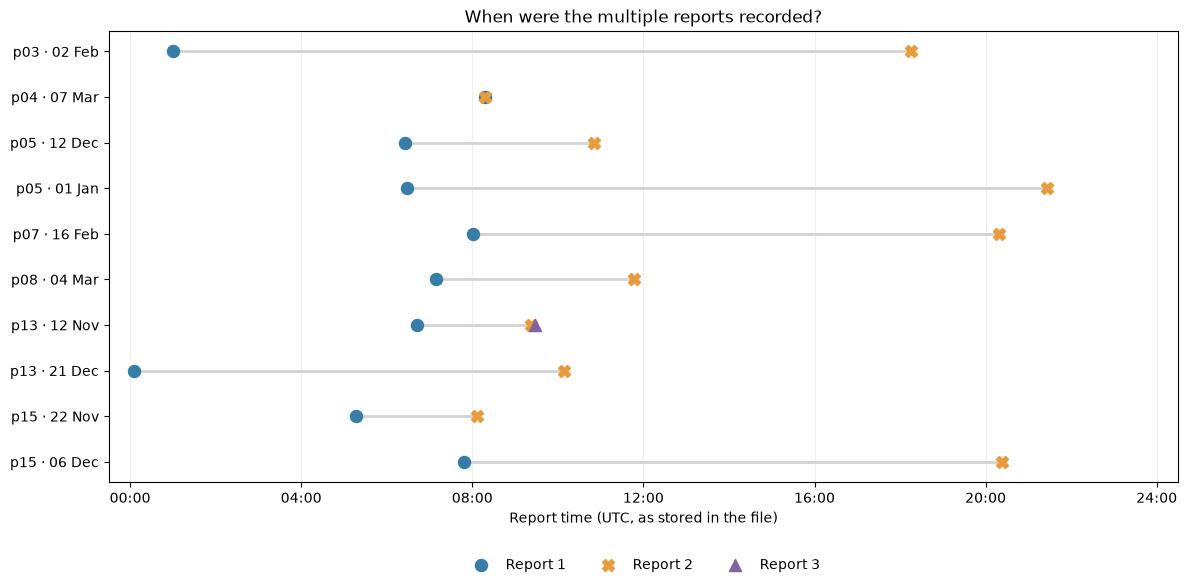

In [572]:
report_points = multiple_wellness_reports.copy()
report_points["case"] = (
    report_points["participant_id"] + " · " + report_points["date"].dt.strftime("%d %b")
)
case_labels = report_points["case"].unique()
report_points["case_number"] = pd.Categorical(
    report_points["case"], categories=case_labels, ordered=True
).codes
report_points["report_hour"] = (
    report_points["reported_at"].dt.hour
    + report_points["reported_at"].dt.minute / 60
    + report_points["reported_at"].dt.second / 3600
)

fig, ax = plt.subplots(figsize=(12, 6))
for case, reports in report_points.groupby("case_number"):
    ax.plot(reports["report_hour"], [case] * len(reports), color="lightgrey", linewidth=2)

for number, color, marker in [(1, "#377da8", "o"), (2, "#e89b3c", "X"), (3, "#8064a2", "^")]:
    points = report_points.loc[report_points["report_number"].eq(number)]
    ax.scatter(
        points["report_hour"], points["case_number"],
        color=color, marker=marker, s=75, label=f"Report {number}", zorder=3,
    )

ax.set_yticks(range(len(case_labels)), case_labels)
ax.invert_yaxis()
ax.set_xticks(range(0, 25, 4), [f"{hour:02d}:00" for hour in range(0, 25, 4)])
ax.set_xlim(-0.5, 24.5)
ax.set_xlabel("Report time (UTC, as stored in the file)")
ax.set_title("When were the multiple reports recorded?")
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
plt.tight_layout()
plt.show()

The 10 prediction days contain 21 reports. Nine days have two reports; p13 has three on 12 November. The first entries for p03 on 2 February and p13 on 21 December are close to midnight. I will treat these as late reports for the previous day. For the other entries, I want to compare the values to see whether any scores changed.

In [573]:
multiple_wellness_reports[[
    "participant_id", "date", "report_number", "report_time", *wellness_features, "prior_day_has_report"
]].style.format({"date": "{:%d %b %Y}"}).hide(axis="index")

participant_id,date,report_number,report_time,stress,fatigue,mood,sleep_quality,prior_day_has_report
p03,02 Feb 2020,1,01:00:28,3,3,3,3,False
p03,02 Feb 2020,2,18:15:39,3,3,3,3,False
p04,07 Mar 2020,1,08:17:42,3,3,3,4,False
p04,07 Mar 2020,2,08:18:13,3,3,3,3,False
p05,12 Dec 2019,1,06:25:44,1,3,1,2,True
p05,12 Dec 2019,2,10:50:32,0,0,0,0,True
p05,01 Jan 2020,1,06:28:07,3,1,3,3,True
p05,01 Jan 2020,2,21:25:53,3,3,3,3,True
p07,16 Feb 2020,1,08:01:35,3,3,3,3,True
p07,16 Feb 2020,2,20:18:26,2,3,3,4,True


I interpret `effective_time_frame` as the date and time the wellness assessment relates to. Fatigue, stress, and mood describe how the participant felt then, while sleep quality refers to the previous night's rest.

For p03 on 2 February and p13 on 21 December, there is no report on the previous date. I will treat their first entries close to midnight as late reports for the previous day and move their assigned dates back by one day. The exception is p04 on 7 March, which will stay on its recorded date.

For the remaining days with multiple reports, I will use the first entry with valid scores.

### 5. Apply the wellness decisions

The changes are applied to a separate copy. The raw files stay unchanged.

In [574]:
wellness_clean = wellness.copy()
wellness_clean["original_date"] = wellness_clean["reported_at"].dt.tz_localize(None).dt.normalize()
wellness_clean["date"] = wellness_clean["original_date"]

for participant, date in [("p03", "2020-02-02"), ("p13", "2019-12-21")]:
    reports = wellness_clean.loc[
        wellness_clean["participant_id"].eq(participant)
        & wellness_clean["date"].eq(pd.Timestamp(date))
    ]
    first_report = reports["reported_at"].idxmin()
    wellness_clean.loc[first_report, "date"] -= pd.Timedelta(days=1)

moved_wellness_reports = wellness_clean.loc[
    wellness_clean["date"].ne(wellness_clean["original_date"]),
    ["participant_id", "reported_at", "original_date", "date"],
].copy()
moved_wellness_reports.style.format({
    "original_date": "{:%d %b %Y}",
    "date": "{:%d %b %Y}",
}).hide(axis="index")

participant_id,reported_at,original_date,date
p03,2020-02-02 01:00:28.003000+00:00,02 Feb 2020,01 Feb 2020
p13,2019-12-21 00:05:56.168000+00:00,21 Dec 2019,20 Dec 2019


In [575]:
valid_wellness_scores = (
    wellness_clean[wellness_features].ge(1)
    & wellness_clean[wellness_features].le(5)
).all(axis=1)
print(f"Reports excluded for scores outside 1–5: {(~valid_wellness_scores).sum()}")

wellness_clean = wellness_clean.loc[valid_wellness_scores].copy()
reports_before_selection = len(wellness_clean)
wellness_clean = (
    wellness_clean.sort_values(["participant_id", "date", "reported_at"])
    .drop_duplicates(["participant_id", "date"], keep="first")
    .copy()
)
print(f"Additional reports excluded after keeping the first valid entry: {reports_before_selection - len(wellness_clean)}")
print(f"Daily wellness reports remaining: {len(wellness_clean):,}")

Reports excluded for scores outside 1–5: 5
Additional reports excluded after keeping the first valid entry: 13
Daily wellness reports remaining: 1,729


In [576]:
wellness_inputs = wellness_clean.set_index(["participant_id", "date"])[
    wellness_features
].rename(columns={"sleep_quality": "previous_sleep_quality"})

model_data_iteration_2 = model_data.join(
    wellness_inputs,
    on=["participant_id", "date"],
    how="inner",
    validate="one_to_one",
)

wellness_cleaning_coverage = wellness_coverage.drop(index="Total")[[
    "Prediction nights", "With same-date report"
]].rename(columns={"With same-date report": "With report before cleaning"}).copy()
wellness_cleaning_coverage["With valid scores after cleaning"] = (
    model_data_iteration_2.groupby("participant_id").size()
    .reindex(wellness_cleaning_coverage.index, fill_value=0)
)
wellness_cleaning_coverage["Without valid scores after cleaning"] = (
    wellness_cleaning_coverage["Prediction nights"]
    - wellness_cleaning_coverage["With valid scores after cleaning"]
)
wellness_cleaning_coverage.loc["Total"] = wellness_cleaning_coverage.sum()
wellness_cleaning_coverage

,Prediction nights,With report before cleaning,With valid scores after cleaning,Without valid scores after cleaning
participant_id,,,,
p01,148,136,136,12
p02,136,93,93,43
p03,56,38,39,17
p04,139,133,132,7
p05,107,97,97,10
p06,147,144,144,3
p07,136,123,123,13
p08,127,90,90,37
p09,117,87,87,30


In [577]:
model_data_iteration_2.describe()

,date,wake_up_hour,previous_bedtime_hour,previous_sleep_minutes,avg_sleep_last_3_nights,steps,session_count,lightly_active_minutes,moderately_active_minutes,very_active_minutes,last_activity,min_since_last_activity,next_sleep_minutes,stress,fatigue,mood,previous_sleep_quality
count,1415,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000,1415.000000
mean,2020-01-13 07:03:20.989399,8.013239,0.175194,405.657951,404.484570,10698.861484,1.059364,3.780919,5.555477,30.907420,1.642403,463.897668,407.981625,2.932155,2.699647,3.231095,3.041696
min,2019-11-01 00:00:00,0.233333,-11.916667,54.000000,54.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000,66.000000,1.000000,1.000000,1.000000,1.000000
25%,2019-12-09 00:00:00,6.566667,-1.016667,359.000000,367.000000,6653.500000,0.000000,0.000000,0.000000,0.000000,0.000000,258.441667,362.000000,3.000000,2.000000,3.000000,3.000000
50%,2020-01-13 00:00:00,7.500000,-0.233333,406.000000,406.666667,10457.000000,1.000000,0.000000,1.000000,18.000000,1.000000,410.066667,407.000000,3.000000,3.000000,3.000000,3.000000
75%,2020-02-15 00:00:00,8.800000,0.750000,454.000000,443.166667,14993.000000,2.000000,4.000000,8.000000,49.000000,2.000000,708.000000,454.000000,3.000000,3.000000,4.000000,4.000000
max,2020-03-30 00:00:00,20.633333,11.616667,733.000000,611.333333,32284.000000,6.000000,93.000000,90.000000,330.000000,18.000000,1239.000000,823.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,2.359304,2.323790,81.334661,58.591386,5800.629344,1.046653,7.965275,9.084679,38.220447,2.334638,267.988334,78.984017,0.712332,0.662893,0.628997,0.758050


After cleaning, 1,415 of the original 1,745 prediction nights have a matching report with all four scores in range. The date shifts recover one night for p03 and one for p13, while two other nights are excluded because of invalid scores. The total stays the same, but the included nights change.

`model_data_iteration_2` contains those 1,415 nights with the existing inputs plus stress, fatigue, mood, and `previous_sleep_quality`. The original `model_data` still contains all 1,745 nights.

Before I proceed with the next table I want to first check whether these new features would have any correlation with following night sleep.

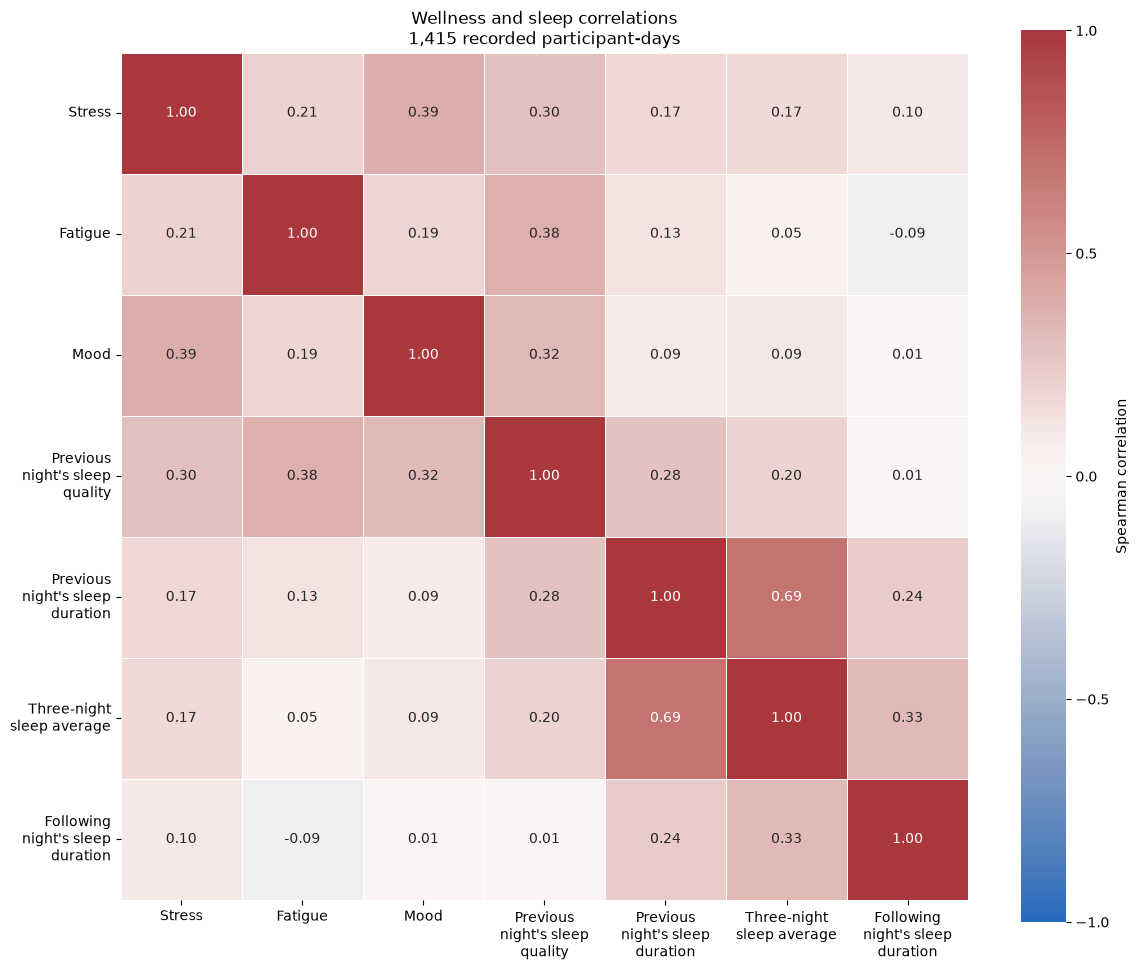

In [578]:
correlation_columns = {
    "stress": "Stress",
    "fatigue": "Fatigue",
    "mood": "Mood",
    "previous_sleep_quality": "Previous\nnight's sleep\nquality",
    "previous_sleep_minutes": "Previous\nnight's sleep\nduration",
    "avg_sleep_last_3_nights": "Three-night\nsleep average",
    "next_sleep_minutes": "Following\nnight's sleep\nduration",
}

correlation_data = model_data_iteration_2[list(correlation_columns)].rename(
    columns=correlation_columns
)
wellness_correlations = correlation_data.corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    wellness_correlations,
    annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5,
    cbar_kws={"label": "Spearman correlation", "ticks": [-1, -0.5, 0, 0.5, 1]},
    ax=ax,
)
ax.set_title(f"Wellness and sleep correlations\n{len(correlation_data):,} recorded participant-days")
ax.tick_params(axis="both", labelsize=10)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The three-night sleep average has the strongest correlation with following-night sleep duration among these inputs (0.33), followed by previous-night duration (0.24).

The wellness scores have little to no correlations with following-night duration: fatigue. Fatigue and previous-night sleep quality are more closely related to each other (0.38) than either is to following-night duration. Non the less, those features are still worth including.

## Nutrition and Fluid Report Exploration

To begin with, I want to start by first exploring the daily reports dataset to see what features we can use from it.

In [579]:
nutrition_example = pd.read_csv(participant_folders[0] / "googledocs/reporting.csv")
nutrition_example.head(10)

,date,timestamp,meals,weight,glasses_of_fluid,alcohol_consumed
0,06/11/2019,06/12/2019 21:58:30,"Breakfast, Dinner",100.0,7,No
1,09/11/2019,09/12/2019 21:17:02,"Breakfast, Evening",100.0,6,No
2,10/11/2019,10/12/2019 21:52:58,"Breakfast, Lunch, Dinner",100.0,9,No
3,11/11/2019,11/11/2019 22:36:30,"Breakfast, Dinner",100.0,5,No
4,12/11/2019,13/11/2019 00:15:47,"Breakfast, Lunch, Dinner",100.0,7,No
5,13/11/2019,13/11/2019 22:08:03,"Breakfast, Dinner, Evening",100.0,6,No
6,14/11/2019,15/11/2019 00:00:47,"Breakfast, Lunch, Dinner, Evening",100.0,8,No
7,15/11/2019,15/12/2019 23:20:39,"Breakfast, Lunch, Dinner",100.0,9,No
8,15/11/2019,15/11/2019 23:38:30,"Breakfast, Lunch, Dinner",100.0,8,No
9,16/11/2019,16/11/2019 21:16:28,"Breakfast, Dinner",100.0,9,No


It seems to contain meal types, `date` is the day being described; `timestamp` records when the report was submitted. The meal types are stored together in one field. The report date and submission date can differ, so the submission date should not replace the day being described.

In [580]:
nutrition_tables = []
for folder in participant_folders:
    report_file = folder / "googledocs/reporting.csv"
    if report_file.is_file():
        records = pd.read_csv(report_file)
        records["participant_id"] = folder.name
        nutrition_tables.append(records)

nutrition_reports = pd.concat(nutrition_tables, ignore_index=True)
nutrition_reports["report_date"] = pd.to_datetime(
    nutrition_reports["date"], format="%d/%m/%Y", errors="coerce"
)
nutrition_reports["submitted_at"] = pd.to_datetime(
    nutrition_reports["timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce"
)
nutrition_reports["extra_same_date"] = nutrition_reports.duplicated(
    ["participant_id", "report_date"]
)

nutrition_answer_columns = [
    "participant_id", "date", "meals", "weight", "glasses_of_fluid", "alcohol_consumed"
]
nutrition_reports["duplicate_answers"] = nutrition_reports.duplicated(nutrition_answer_columns)

print(f"Reports: {len(nutrition_reports):,}")
print(f"Exact duplicate rows: {nutrition_reports.duplicated([*nutrition_answer_columns, 'timestamp']).sum()}")
print(f"Repeated answers ignoring submission time: {nutrition_reports['duplicate_answers'].sum()}")
print(f"Unreadable report dates: {nutrition_reports['report_date'].isna().sum()}")
print(f"Unreadable submission times: {nutrition_reports['submitted_at'].isna().sum()}")
print("Missing entries:", nutrition_reports[["meals", "glasses_of_fluid", "alcohol_consumed"]].isna().sum().to_dict())

nutrition_coverage = nutrition_reports.groupby("participant_id").agg(**{
    "Reports": ("report_date", "size"),
    "Reported days": ("report_date", "nunique"),
    "Extra same-date reports": ("extra_same_date", "sum"),
    "Repeated answers (ignoring time)": ("duplicate_answers", "sum"),
}).reindex([folder.name for folder in participant_folders], fill_value=0)
nutrition_coverage.loc["Total"] = nutrition_coverage.sum()
nutrition_coverage

Reports: 1,569
Exact duplicate rows: 0
Repeated answers ignoring submission time: 95
Unreadable report dates: 0
Unreadable submission times: 0
Missing entries: {'meals': 0, 'glasses_of_fluid': 0, 'alcohol_consumed': 0}


,Reports,Reported days,Extra same-date reports,Repeated answers (ignoring time)
participant_id,,,,
p01,109,100,9,0
p02,153,87,66,64
p03,117,113,4,1
p04,139,131,8,1
p05,126,117,9,3
p06,129,110,19,15
p07,126,118,8,2
p08,58,57,1,0
p09,98,97,1,0


There are 1,569 reports from 15 participants; p15 has no daily-report file. None of the meal, fluid, or alcohol fields is empty, and all dates and submission times could be parsed.

There are no exact duplicate rows, but 136 participant-days have multiple reports, producing 158 extra entries. These need inspecting before choosing one report per day.

Ignoring submission times reveals 95 extra reports with the same participant, reported date, meals, weight, fluid intake, and alcohol answer. Participant p02 accounts for 64 of these.

### Nutrition reports for Iteration 2 nights

These views match nutrition reports to `model_data_iteration_2` by participant and reported date. Nights without a report remain visible; submission dates are not used to move reports.

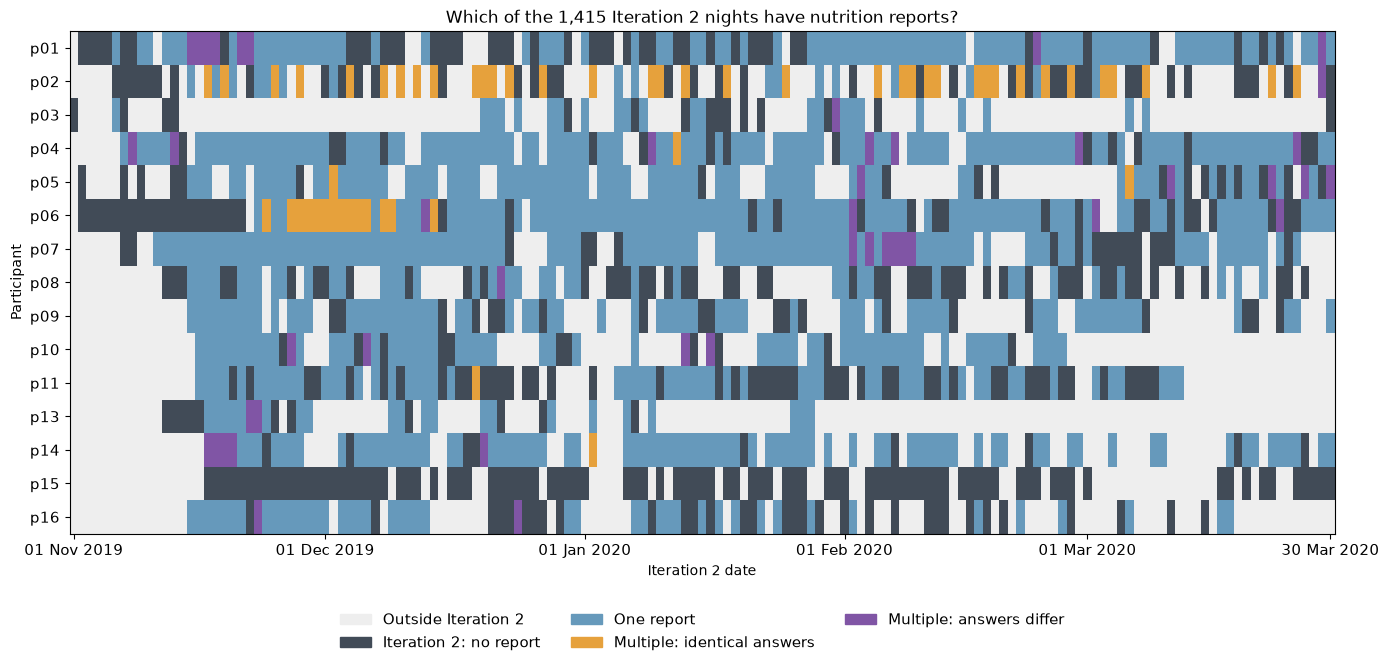

,Iteration 2 nights,Without report,One report,Multiple: identical answers,Multiple: answers differ
Participant,,,,,
p01,136,43,85,0,8
p02,93,39,17,36,1
p03,39,15,23,0,1
p04,132,15,109,1,7
p05,97,18,72,2,5
p06,144,39,87,14,4
p07,123,18,99,0,6
p08,90,50,39,0,1
p09,87,20,67,0,0


In [581]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

model_data_iteration_2_before_nutrition = model_data_iteration_2.copy()

nutrition_day_keys = ["participant_id", "report_date"]
nutrition_iteration_2_nights = model_data_iteration_2[["participant_id", "date"]].rename(
    columns={"date": "report_date"}
).copy()
nutrition_diagnostics = nutrition_reports.merge(
    nutrition_iteration_2_nights, on=nutrition_day_keys, how="inner", validate="many_to_one",
)
nutrition_diagnostics["gap_days"] = (
    nutrition_diagnostics["submitted_at"].dt.normalize()
    - nutrition_diagnostics["report_date"]
).dt.days

nutrition_report_counts = nutrition_diagnostics.groupby(nutrition_day_keys).size()
nutrition_answer_counts = (
    nutrition_diagnostics.drop_duplicates(nutrition_answer_columns)
    .groupby(nutrition_day_keys).size()
)
nutrition_days = nutrition_iteration_2_nights.set_index(nutrition_day_keys)
nutrition_days["reports"] = nutrition_report_counts.reindex(nutrition_days.index, fill_value=0)
nutrition_days["different_answers"] = nutrition_answer_counts.reindex(nutrition_days.index, fill_value=0)
nutrition_days["status"] = np.select(
    [nutrition_days["reports"].eq(0), nutrition_days["reports"].eq(1),
     nutrition_days["different_answers"].eq(1)],
    [1, 2, 3], default=4,
)

nutrition_participants = sorted(nutrition_iteration_2_nights["participant_id"].unique())
nutrition_dates = pd.date_range(
    nutrition_iteration_2_nights["report_date"].min(),
    nutrition_iteration_2_nights["report_date"].max(),
)
nutrition_date_ticks = [i for i, day in enumerate(nutrition_dates) if day.day == 1]
nutrition_date_ticks = sorted(set([0, *nutrition_date_ticks, len(nutrition_dates) - 1]))
nutrition_date_labels = [nutrition_dates[i].strftime("%d %b %Y") for i in nutrition_date_ticks]
nutrition_day_map = nutrition_days["status"].unstack("report_date").reindex(
    index=nutrition_participants, columns=nutrition_dates,
).fillna(0)

nutrition_status_colors = ["#eeeeee", "#414b57", "#6699bb", "#e6a13c", "#8055a5"]
nutrition_status_labels = [
    "Outside Iteration 2", "Iteration 2: no report", "One report",
    "Multiple: identical answers", "Multiple: answers differ",
]
fig, ax = plt.subplots(figsize=(14, 6.8))
ax.imshow(nutrition_day_map, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(nutrition_status_colors), vmin=-0.5, vmax=4.5)
ax.set(yticks=range(len(nutrition_participants)), yticklabels=nutrition_participants,
       xticks=nutrition_date_ticks, xticklabels=nutrition_date_labels,
       xlabel="Iteration 2 date", ylabel="Participant",
       title=f"Which of the {len(nutrition_days):,} Iteration 2 nights have nutrition reports?")
ax.tick_params(labelsize=11)
ax.legend(handles=[Patch(color=color, label=label) for color, label in
                   zip(nutrition_status_colors, nutrition_status_labels)],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=11)
fig.tight_layout()
plt.show()

nutrition_night_summary = pd.crosstab(
    nutrition_days.index.get_level_values("participant_id"), nutrition_days["status"],
).reindex(index=nutrition_participants, columns=[1, 2, 3, 4], fill_value=0)
nutrition_night_summary.columns = [
    "Without report", "One report", "Multiple: identical answers", "Multiple: answers differ",
]
nutrition_night_summary.insert(0, "Iteration 2 nights", nutrition_night_summary.sum(axis=1))
nutrition_night_summary.loc["Total"] = nutrition_night_summary.sum()
nutrition_night_summary.rename_axis("Participant")

Of the 1,415 Iteration 2 nights, 955 have at least one matching nutrition report and 460 have none. Among the matching nights, 101 have multiple reports: 55 with identical answers and 46 with different answers.

I will apply the following cleaning decisions:

- Remove the nights without a matching nutrition report. This includes all nights from p15, who has NO daily report file.
- Remove identical same day copies. Keep the earliest copy submitted on or after its reported date when one is available.
- Keep reports with different answers and flag any remaining entries submitted before their reported date for inspection.

In [582]:
nutrition_candidates = nutrition_diagnostics.copy()
nutrition_candidates["valid_date_order"] = nutrition_candidates["gap_days"].ge(0)

nutrition_deduplicated = (
    nutrition_candidates.sort_values(
        ["valid_date_order", "submitted_at"], ascending=[False, True], kind="stable",
    )
    .drop_duplicates(nutrition_answer_columns, keep="first")
    .drop(columns=["extra_same_date", "duplicate_answers"])
    .sort_values(["participant_id", "report_date", "submitted_at"])
    .copy()
)
nutrition_duplicate_copies = nutrition_diagnostics.loc[
    ~nutrition_diagnostics.index.isin(nutrition_deduplicated.index)
].copy()
nutrition_clean = nutrition_deduplicated.loc[
    nutrition_deduplicated["valid_date_order"]
].copy()
nutrition_date_review = nutrition_deduplicated.loc[
    ~nutrition_deduplicated["valid_date_order"]
].copy()
nutrition_clean_days = nutrition_clean.groupby(nutrition_day_keys).size().rename("reports")

nutrition_matched_keys = pd.MultiIndex.from_frame(
    nutrition_deduplicated[nutrition_day_keys]
)
nights_with_nutrition = pd.MultiIndex.from_frame(
    model_data_iteration_2_before_nutrition[["participant_id", "date"]]
).isin(nutrition_matched_keys)
iteration_2_nights_without_nutrition = model_data_iteration_2_before_nutrition.loc[
    ~nights_with_nutrition
].copy()
model_data_iteration_2 = model_data_iteration_2_before_nutrition.loc[
    nights_with_nutrition
].copy()

print(f"Nights without a nutrition report removed: {len(iteration_2_nights_without_nutrition)}")
print(f"Iteration 2 nights remaining: {len(model_data_iteration_2):,}")
print(f"Identical report copies removed: {len(nutrition_duplicate_copies)}")

Nights without a nutrition report removed: 460
Iteration 2 nights remaining: 955
Identical report copies removed: 66


### Remaining Iteration 2 nights

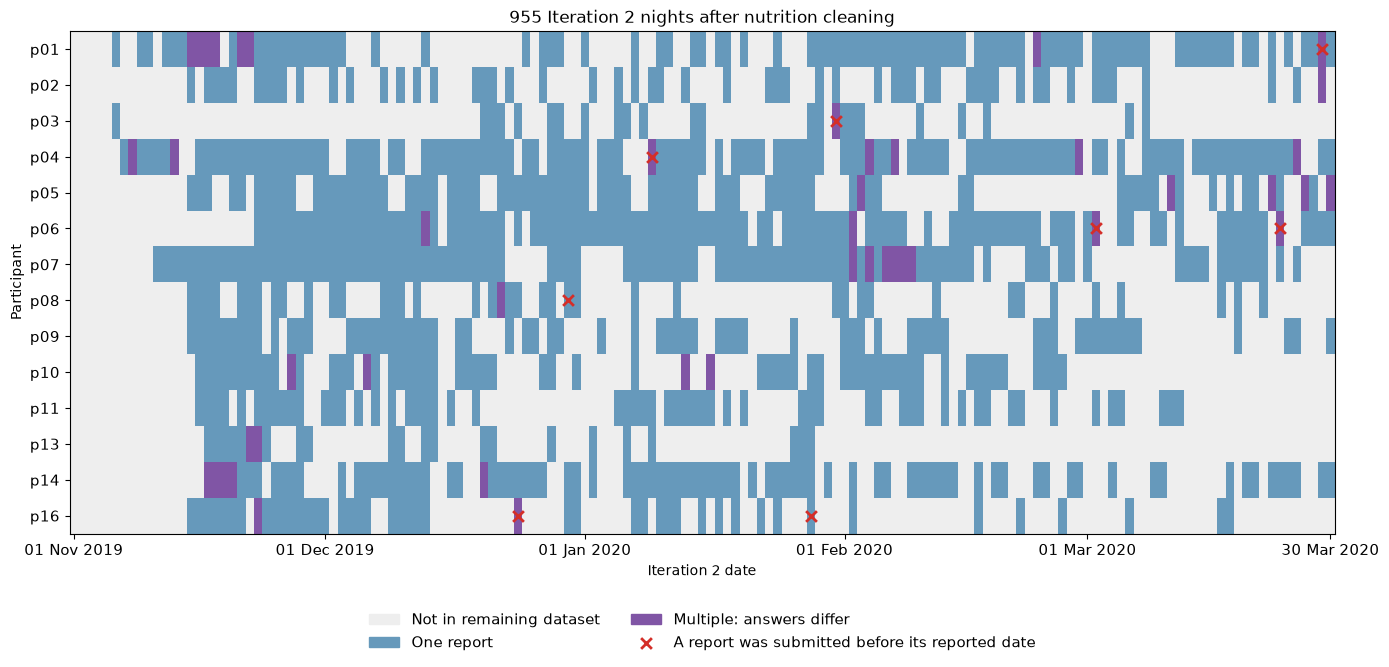

In [583]:
nutrition_remaining_days = nutrition_deduplicated.groupby(nutrition_day_keys).agg(
    reports=("submitted_at", "size"),
    date_problem=("valid_date_order", lambda valid: (~valid).any()),
)
nutrition_remaining_nights = (
    model_data_iteration_2[["participant_id", "date"]]
    .rename(columns={"date": "report_date"})
    .set_index(nutrition_day_keys)
    .join(nutrition_remaining_days, how="left", validate="one_to_one")
)
nutrition_remaining_nights["status"] = np.where(
    nutrition_remaining_nights["reports"].eq(1), 1, 2,
)
nutrition_remaining_participants = sorted(
    nutrition_remaining_nights.index.get_level_values("participant_id").unique()
)
nutrition_remaining_map = nutrition_remaining_nights["status"].unstack("report_date").reindex(
    index=nutrition_remaining_participants, columns=nutrition_dates,
).fillna(0)

remaining_colors = ["#eeeeee", "#6699bb", "#8055a5"]
remaining_labels = ["Not in remaining dataset", "One report", "Multiple: answers differ"]
fig, ax = plt.subplots(figsize=(14, 6.8))
ax.imshow(nutrition_remaining_map, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(remaining_colors), vmin=-0.5, vmax=2.5)
flagged_nights = nutrition_remaining_nights.loc[
    nutrition_remaining_nights["date_problem"]
].reset_index()
ax.scatter(
    [nutrition_dates.get_loc(day) for day in flagged_nights["report_date"]],
    [nutrition_remaining_participants.index(person) for person in flagged_nights["participant_id"]],
    marker="x", s=60, linewidths=2, color="#d42e28", zorder=3,
    label="A report was submitted before its reported date",
)
ax.set(yticks=range(len(nutrition_remaining_participants)), yticklabels=nutrition_remaining_participants,
       xticks=nutrition_date_ticks, xticklabels=nutrition_date_labels,
       xlabel="Iteration 2 date", ylabel="Participant",
       title=f"{len(model_data_iteration_2):,} Iteration 2 nights after nutrition cleaning")
ax.tick_params(labelsize=11)
legend_handles = [Patch(color=color, label=label) for color, label in zip(remaining_colors, remaining_labels)]
legend_handles.append(ax.collections[-1])
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=2, frameon=False, fontsize=11)
fig.tight_layout()
plt.show()

Okay, so now we can clearly see reports submitted before the days they describe (marked with an X), which appear to be incorrect. Before dropping them, I want to explore them all and see whether there might be an explanation, as there was with the wellness reports. Perhaps someone accidentally entered a future date. Nonetheless, there are only a few of these cases, so excluding them completely would not be too big a loss.

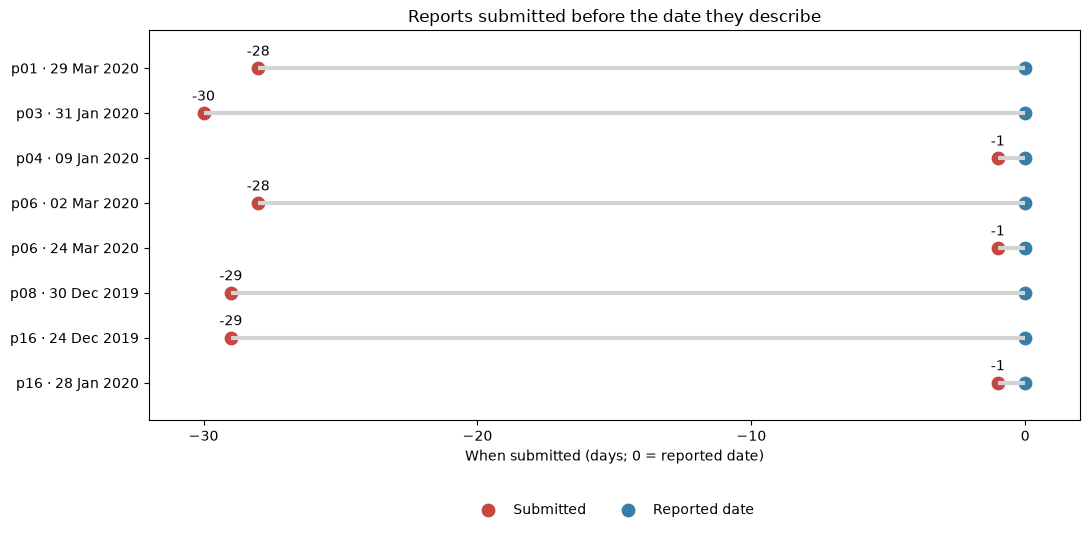

In [584]:
early_nutrition_reports = nutrition_deduplicated.loc[
    nutrition_deduplicated["gap_days"].lt(0)
].sort_values(["participant_id", "report_date"]).copy()

labels = early_nutrition_reports["participant_id"] + " · " + early_nutrition_reports["report_date"].dt.strftime("%d %b %Y")
positions = range(len(early_nutrition_reports))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hlines(positions, early_nutrition_reports["gap_days"], 0, color="lightgrey", linewidth=3)
ax.scatter(early_nutrition_reports["gap_days"], positions, color="#c54740", s=80, label="Submitted")
ax.scatter([0] * len(early_nutrition_reports), positions, color="#377da8", s=80, label="Reported date")
for row, days in enumerate(early_nutrition_reports["gap_days"]):
    ax.annotate(f"{days}", (days, row), xytext=(0, 9), textcoords="offset points", ha="center")
ax.set_yticks(positions, labels)
ax.margins(y=0.12)
ax.invert_yaxis()
ax.set_xlim(early_nutrition_reports["gap_days"].min() - 2, 2)
ax.set_xticks([-30, -20, -10, 0])
ax.set_xlabel("When submitted (days; 0 = reported date)")
ax.set_title("Reports submitted before the date they describe")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [585]:
early_nutrition_reports[[
    "participant_id", "report_date", "submitted_at", "gap_days",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Reported date",
    "submitted_at": "Submitted at", "gap_days": "Gap (days)",
}).style.hide(axis="index").format({
    "Reported date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M:%S}",
    "Gap (days)": "{:+d}",
})

Participant,Reported date,Submitted at,Gap (days)
p01,29 Mar 2020,01 Mar 2020 23:13:54,-28
p03,31 Jan 2020,01 Jan 2020 00:16:13,-30
p04,09 Jan 2020,08 Jan 2020 19:54:33,-1
p06,02 Mar 2020,03 Feb 2020 22:38:15,-28
p06,24 Mar 2020,23 Mar 2020 22:18:12,-1
p08,30 Dec 2019,01 Dec 2019 09:31:19,-29
p16,24 Dec 2019,25 Nov 2019 09:35:45,-29
p16,28 Jan 2020,27 Jan 2020 16:41:07,-1


The 28–30 day differences may come from incorrectly entered months. Several of these reports were submitted around the start of a month. For example, p01's report for 29 March, submitted on 1 March, might describe 29 February 2020, which was already a leap year. The proposed date for these five entries is one month earlier on the same number date indicated.

For the entries submitted one day early, the proposed date is the submission date. I would only move an entry if the proposed date has no report already. The table checks the proposed date, using the participant and the day each report describes. It also checks whether the proposed date has a night in the original Iteration 2 dataset. These are proposals; no dates have been changed.

In [586]:
date_comparison = early_nutrition_reports[["participant_id", "report_date", "submitted_at", "gap_days"]].copy()
date_comparison["proposed_date"] = date_comparison["report_date"] - pd.DateOffset(months=1)
one_day_early = date_comparison["gap_days"].eq(-1)
date_comparison.loc[one_day_early, "proposed_date"] = (
    date_comparison.loc[one_day_early, "submitted_at"].dt.normalize()
)

reported_dates = set(zip(nutrition_reports["participant_id"], nutrition_reports["report_date"]))
iteration_2_dates = set(zip(
    model_data_iteration_2_before_nutrition["participant_id"], model_data_iteration_2_before_nutrition["date"],
))
date_comparison["proposed_date_has_report"] = [
    (person, day) in reported_dates for person, day in zip(date_comparison["participant_id"], date_comparison["proposed_date"])
]
date_comparison["proposed_night_in_iteration_2"] = [
    (person, day) in iteration_2_dates for person, day in zip(date_comparison["participant_id"], date_comparison["proposed_date"])
]

date_comparison[[
    "participant_id", "report_date", "submitted_at",
    "proposed_date", "proposed_date_has_report", "proposed_night_in_iteration_2",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Current reported date", "submitted_at": "Submitted at",
    "proposed_date": "Proposed date", "proposed_date_has_report": "Proposed date has report",
    "proposed_night_in_iteration_2": "Proposed night in Iteration 2",
}).style.hide(axis="index").format({
    "Current reported date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M:%S}",
    "Proposed date": "{:%d %b %Y}",
})

Participant,Current reported date,Submitted at,Proposed date,Proposed date has report,Proposed night in Iteration 2
p01,29 Mar 2020,01 Mar 2020 23:13:54,29 Feb 2020,True,True
p03,31 Jan 2020,01 Jan 2020 00:16:13,31 Dec 2019,False,False
p04,09 Jan 2020,08 Jan 2020 19:54:33,08 Jan 2020,False,True
p06,02 Mar 2020,03 Feb 2020 22:38:15,02 Feb 2020,True,True
p06,24 Mar 2020,23 Mar 2020 22:18:12,23 Mar 2020,False,True
p08,30 Dec 2019,01 Dec 2019 09:31:19,30 Nov 2019,False,True
p16,24 Dec 2019,25 Nov 2019 09:35:45,24 Nov 2019,True,True
p16,28 Jan 2020,27 Jan 2020 16:41:07,27 Jan 2020,False,True


p03 will be entirely removed as there is no equivelant to the proposed night in the iteration 2 dataset. P04, P06 (23 Mar), p08, p16(28 Jan) will be moved to the proposed dates, and the other entries that already have reports for the proposed dates will be entirely scrapped.

In [587]:
move_report = (
    ~date_comparison["proposed_date_has_report"]
    & date_comparison["proposed_night_in_iteration_2"]
)
nutrition_date_actions = date_comparison.copy()
nutrition_date_actions["Action"] = np.where(move_report, "Moved", "Removed")

nutrition_clean = nutrition_deduplicated.copy()
nutrition_clean.loc[date_comparison.index[move_report], "report_date"] = (
    date_comparison.loc[move_report, "proposed_date"]
)
nutrition_removed_reports = nutrition_clean.loc[date_comparison.index[~move_report]].copy()
nutrition_clean = nutrition_clean.drop(index=nutrition_removed_reports.index).copy()
nutrition_clean["date"] = nutrition_clean["report_date"].dt.strftime("%d/%m/%Y")
nutrition_clean["gap_days"] = (
    nutrition_clean["submitted_at"].dt.normalize() - nutrition_clean["report_date"]
).dt.days
nutrition_clean["valid_date_order"] = nutrition_clean["gap_days"].ge(0)
nutrition_date_review = nutrition_clean.loc[~nutrition_clean["valid_date_order"]].copy()
nutrition_clean_days = nutrition_clean.groupby(nutrition_day_keys).size().rename("reports")

nutrition_matched_keys = pd.MultiIndex.from_frame(nutrition_clean[nutrition_day_keys])
nights_with_nutrition = pd.MultiIndex.from_frame(
    model_data_iteration_2_before_nutrition[["participant_id", "date"]]
).isin(nutrition_matched_keys)
model_data_iteration_2 = model_data_iteration_2_before_nutrition.loc[nights_with_nutrition].copy()
iteration_2_nights_without_nutrition = model_data_iteration_2_before_nutrition.loc[~nights_with_nutrition].copy()

print(f"Reports moved: {move_report.sum()}")
print(f"Flagged reports removed: {(~move_report).sum()}")
print(f"Reports still submitted before their stated date: {len(nutrition_date_review)}")
print(f"Iteration 2 nights remaining: {len(model_data_iteration_2)}")

Reports moved: 4
Flagged reports removed: 4
Reports still submitted before their stated date: 0
Iteration 2 nights remaining: 957


Next I need to look deeper into the multiple entries during the same day. More specifically I want to find out if there are any groups or clusters we can make with the data we have.

In [588]:
nutrition_multiple_reports = nutrition_clean.loc[
    nutrition_clean.duplicated(nutrition_day_keys, keep=False)
].sort_values(["participant_id", "report_date", "submitted_at"]).copy()
nutrition_multiple_reports["report_number"] = (
    nutrition_multiple_reports.groupby(nutrition_day_keys).cumcount() + 1
)
nutrition_multiple_reports["hours_after_date"] = (
    nutrition_multiple_reports["submitted_at"] - nutrition_multiple_reports["report_date"]
).dt.total_seconds() / 3600

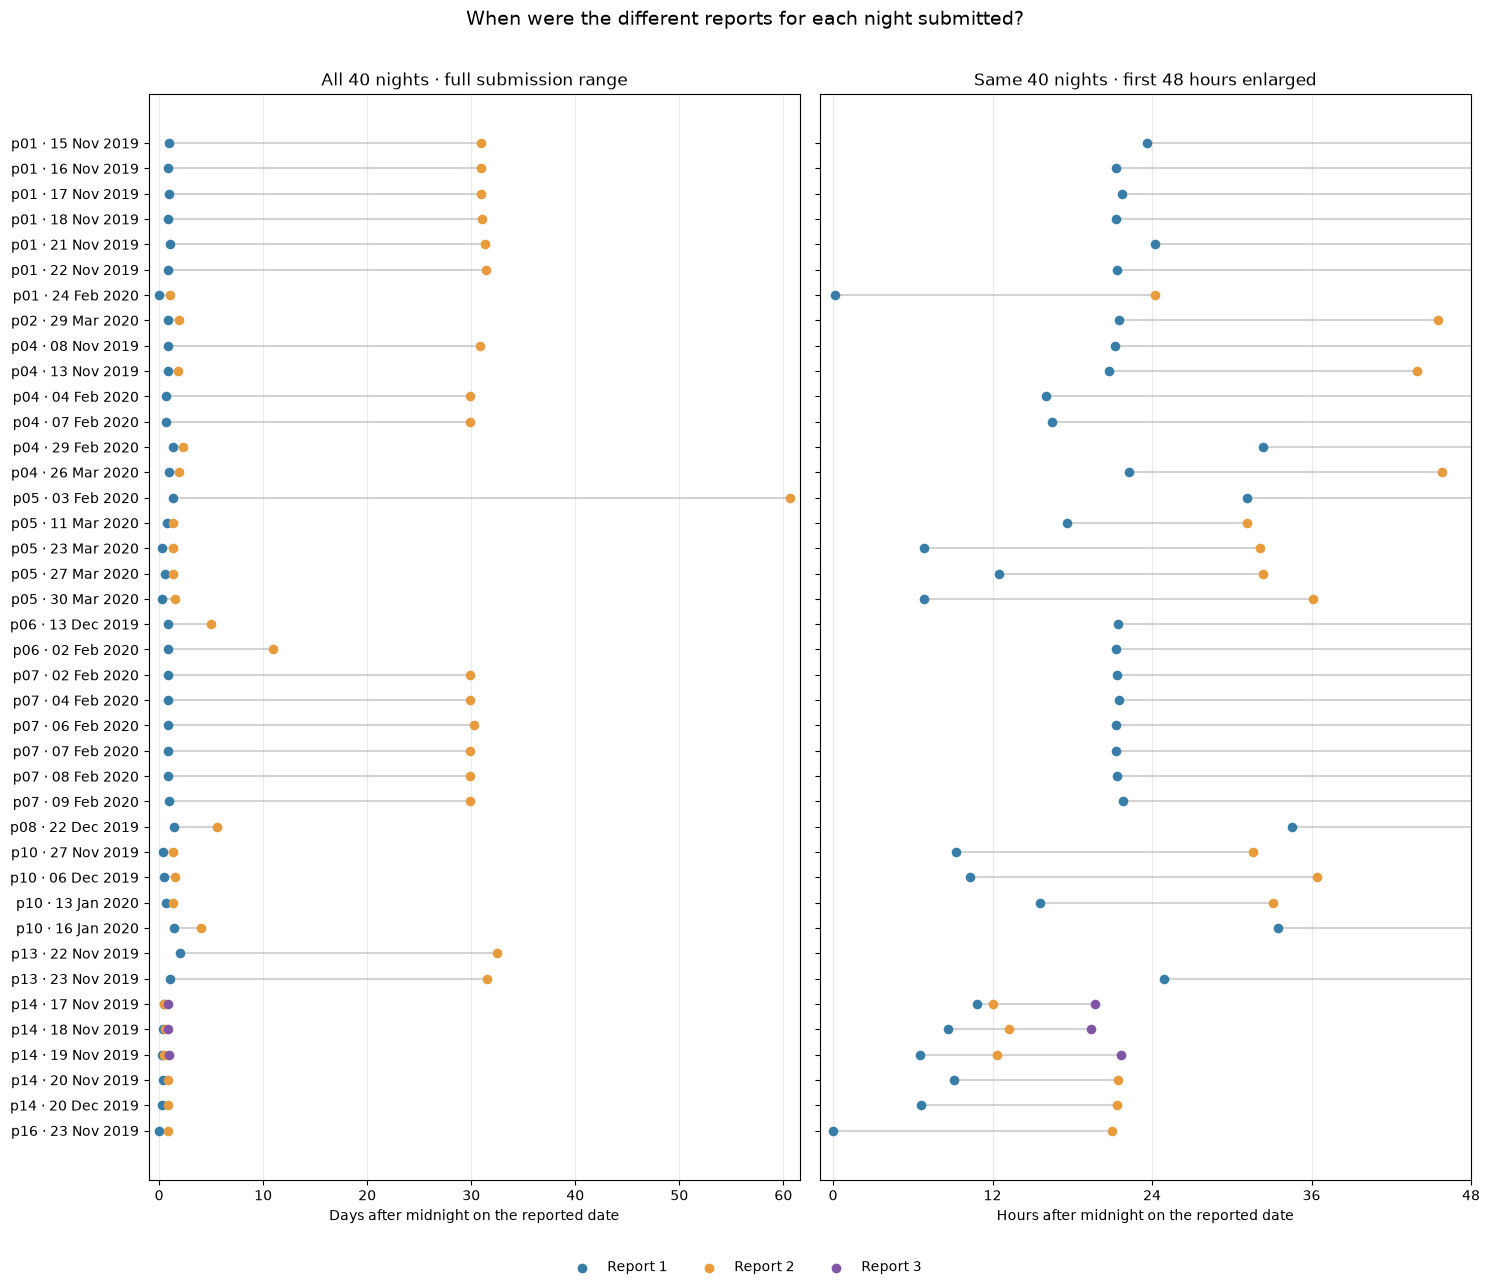

In [589]:
fig, axes = plt.subplots(1, 2, figsize=(15, 13), sharey=True)
report_colors = ["#377da8", "#e89b3c", "#8055a5"]
night_labels = []
for row, ((person, day), reports) in enumerate(nutrition_multiple_reports.groupby(nutrition_day_keys)):
    night_labels.append(f"{person} · {day:%d %b %Y}")
    hours = reports["hours_after_date"]
    for ax, scale in zip(axes, [24, 1]):
        ax.plot(hours / scale, [row] * len(reports), color="lightgray", zorder=1)
        for number, hour in zip(reports["report_number"], hours):
            ax.scatter(hour / scale, row, color=report_colors[number - 1], s=35, zorder=2)

axes[0].set_yticks(range(len(night_labels)), night_labels)
axes[0].invert_yaxis()
axes[0].set_title("All 40 nights · full submission range")
axes[0].set_xlabel("Days after midnight on the reported date")
axes[0].set_xlim(-1, nutrition_multiple_reports["hours_after_date"].max() / 24 + 1)
axes[1].set_title("Same 40 nights · first 48 hours enlarged")
axes[1].set_xlabel("Hours after midnight on the reported date")
axes[1].set_xlim(-1, 48)
axes[1].set_xticks([0, 12, 24, 36, 48])
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
for number, color in enumerate(report_colors, start=1):
    axes[0].scatter([], [], color=color, label=f"Report {number}")
fig.legend(loc="lower center", ncol=3, frameon=False)
fig.suptitle("When were the different reports for each night submitted?", fontsize=14)
plt.tight_layout(rect=[0, 0.035, 1, 0.97])
plt.show()

The chart shows a few patterns worth checking:

- Several p01, p04 and p07 nights have a second submission roughly a month later. These may be date-entry mistakes, similar to the earlier reports submitted before their stated dates, but the timing alone does not confirm this.
- For p14 on 17–20 November, the reports are hours apart within the same day, with up to three entries per day. These could be separate meal records, so I need to compare their answers before deciding what to keep.

Both panels show the same 40 nights. The right panel enlarges the first 48 hours; later submissions remain visible on the left.

In [590]:
same_day_reports = nutrition_multiple_reports.groupby(nutrition_day_keys).filter(
    lambda reports: reports["submitted_at"].dt.normalize().nunique() == 1
)

same_day_reports[[
    "participant_id", "report_date", "report_number", "submitted_at",
    "meals", "glasses_of_fluid", "weight", "alcohol_consumed",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Reported date",
    "report_number": "Report", "submitted_at": "Submitted at",
    "meals": "Meals", "glasses_of_fluid": "Glasses of fluid",
    "weight": "Weight (kg)", "alcohol_consumed": "Alcohol",
}).style.hide(axis="index").format({
    "Reported date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M}",
    "Weight (kg)": "{:.1f}",
})

Participant,Reported date,Report,Submitted at,Meals,Glasses of fluid,Weight (kg),Alcohol
p14,17 Nov 2019,1,17 Nov 2019 10:49,Breakfast,5,74.0,No
p14,17 Nov 2019,2,17 Nov 2019 12:01,Lunch,2,74.0,No
p14,17 Nov 2019,3,17 Nov 2019 19:40,Dinner,3,74.0,No
p14,18 Nov 2019,1,18 Nov 2019 08:39,Breakfast,3,74.0,No
p14,18 Nov 2019,2,18 Nov 2019 13:16,Lunch,1,74.0,No
p14,18 Nov 2019,3,18 Nov 2019 19:25,Dinner,2,74.0,No
p14,19 Nov 2019,1,19 Nov 2019 06:31,Breakfast,2,74.0,No
p14,19 Nov 2019,2,19 Nov 2019 12:19,Lunch,1,74.0,No
p14,19 Nov 2019,3,19 Nov 2019 21:40,Dinner,2,74.0,No
p14,20 Nov 2019,1,20 Nov 2019 09:04,Breakfast,3,74.0,No


The six nights show different patterns:

- **p14, 17–20 November:** the reports name separate meals. Fluid counts sometimes decrease between submissions, so they do not look like a running daily total on these days, so I will just add up the values into a single row.
- **p14, 20 December:** both reports list the same meals, but the fluid count changes from 11 to 12. This could be an update to the daily report, or it might be an entry for the prior day.
- **p16, 23 November:** likely what happened is that the user sort of forgot to enter the data for the previous day and it carried into 23 Nov, an indicator of this is the timestamp at 00:01. So the thing I should take as source of truth for 23 Nov is the second entry at 21:01.

I need to check the nights before for the specific cases of 20 Dec and 23 Nov, the rest of the data from 17 - 20 Nov will be added up for the respective days.

In [591]:
p14_meal_days = nutrition_clean["participant_id"].eq("p14") & nutrition_clean["report_date"].between(
    "2019-11-17", "2019-11-20"
)
p14_meal_reports = nutrition_clean.loc[p14_meal_days].sort_values("submitted_at").copy()
p14_meal_reports["meals"] = p14_meal_reports.groupby(nutrition_day_keys)["meals"].transform(
    ", ".join
)
p14_meal_reports["glasses_of_fluid"] = p14_meal_reports.groupby(nutrition_day_keys)[
    "glasses_of_fluid"
].transform("sum")
combined_p14_reports = p14_meal_reports.drop_duplicates(nutrition_day_keys, keep="last")
nutrition_clean = pd.concat([
    nutrition_clean.loc[~p14_meal_days], combined_p14_reports
]).sort_values(["participant_id", "report_date", "submitted_at"])
nutrition_clean_days = nutrition_clean.groupby(nutrition_day_keys).size().rename("reports")

remaining_same_day_reports = same_day_reports.loc[
    ~(same_day_reports["participant_id"].eq("p14")
      & same_day_reports["report_date"].between("2019-11-17", "2019-11-20"))
].copy()
reported_dates = set(zip(nutrition_reports["participant_id"], nutrition_reports["report_date"]))
remaining_same_day_reports["previous_day_has_report"] = [
    (person, day - pd.Timedelta(days=1)) in reported_dates
    for person, day in zip(remaining_same_day_reports["participant_id"], remaining_same_day_reports["report_date"])
]

remaining_same_day_reports["previous_day_in_iteration_2"] = [
    (person, day - pd.Timedelta(days=1)) in iteration_2_dates
    for person, day in zip(remaining_same_day_reports["participant_id"], remaining_same_day_reports["report_date"])
]

remaining_same_day_reports[[
    "participant_id", "report_date", "report_number", "submitted_at",
    "meals", "glasses_of_fluid", "previous_day_has_report", "previous_day_in_iteration_2",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Reported date", "report_number": "Report",
    "submitted_at": "Submitted at", "meals": "Meals", "glasses_of_fluid": "Glasses of fluid",
    "previous_day_has_report": "Previous day has report",
    "previous_day_in_iteration_2": "Previous day in Iteration 2",
}).style.hide(axis="index").format({
    "Reported date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M}",
})

Participant,Reported date,Report,Submitted at,Meals,Glasses of fluid,Previous day has report,Previous day in Iteration 2
p14,20 Dec 2019,1,20 Dec 2019 06:36,"Breakfast, Lunch, Dinner",11,False,True
p14,20 Dec 2019,2,20 Dec 2019 21:21,"Breakfast, Lunch, Dinner",12,False,True
p16,23 Nov 2019,1,23 Nov 2019 00:01,"Lunch, Dinner",5,False,True
p16,23 Nov 2019,2,23 Nov 2019 21:01,"Breakfast, Dinner",5,False,True


I will assume the earlier submission in each pair describes the previous day:

- **p14:** the report submitted on 20 December at 06:36 is assigned to 19 December 2019.
- **p16:** the report submitted on 23 November at 00:01 is assigned to 22 November 2019.

Both previous nights are in the original Iteration 2 dataset and have no nutrition report. The later submissions stay on their original dates. This adds two matched nights, increasing the working dataset size :D

In [592]:
reports_to_move = remaining_same_day_reports.groupby(nutrition_day_keys).head(1)
nutrition_clean.loc[reports_to_move.index, "report_date"] = (
    reports_to_move["report_date"] - pd.Timedelta(days=1)
)
nutrition_clean["date"] = nutrition_clean["report_date"].dt.strftime("%d/%m/%Y")
nutrition_clean["gap_days"] = (
    nutrition_clean["submitted_at"].dt.normalize() - nutrition_clean["report_date"]
).dt.days
nutrition_clean["valid_date_order"] = nutrition_clean["gap_days"].ge(0)
nutrition_clean = nutrition_clean.sort_values(["participant_id", "report_date", "submitted_at"])
nutrition_clean_days = nutrition_clean.groupby(nutrition_day_keys).size().rename("reports")

nutrition_matched_keys = pd.MultiIndex.from_frame(nutrition_clean[nutrition_day_keys])
nights_with_nutrition = pd.MultiIndex.from_frame(
    model_data_iteration_2_before_nutrition[["participant_id", "date"]]
).isin(nutrition_matched_keys)
model_data_iteration_2 = model_data_iteration_2_before_nutrition.loc[nights_with_nutrition].copy()
iteration_2_nights_without_nutrition = model_data_iteration_2_before_nutrition.loc[~nights_with_nutrition].copy()

print(f"Iteration 2 nights with nutrition reports: {len(model_data_iteration_2)}")
nutrition_clean.loc[reports_to_move.index, [
    "participant_id", "report_date", "submitted_at", "meals", "glasses_of_fluid",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Assigned date",
    "submitted_at": "Submitted at", "meals": "Meals", "glasses_of_fluid": "Glasses of fluid",
}).style.hide(axis="index").format({
    "Assigned date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M}",
})

Iteration 2 nights with nutrition reports: 959


Participant,Assigned date,Submitted at,Meals,Glasses of fluid
p14,19 Dec 2019,20 Dec 2019 06:36,"Breakfast, Lunch, Dinner",11
p16,22 Nov 2019,23 Nov 2019 00:01,"Lunch, Dinner",5


In [593]:
conflicting_reports = nutrition_clean.loc[
    nutrition_clean.duplicated(nutrition_day_keys, keep=False)
].sort_values(["participant_id", "report_date", "submitted_at"]).copy()
conflicting_reports["report_number"] = conflicting_reports.groupby(nutrition_day_keys).cumcount() + 1
second_submission_dates = conflicting_reports.groupby(nutrition_day_keys)[
    "submitted_at"
].transform("max").dt.normalize()
conflicting_reports["second_submission_date_has_report"] = [
    (person, day) in reported_dates
    for person, day in zip(conflicting_reports["participant_id"], second_submission_dates)
]
nutrition_comparison = conflicting_reports[[
    "participant_id", "report_date", "report_number", "submitted_at",
    "meals", "glasses_of_fluid", "weight", "alcohol_consumed", "second_submission_date_has_report",
]].rename(columns={
    "participant_id": "Participant", "report_date": "Reported date", "report_number": "Report",
    "submitted_at": "Submitted at", "meals": "Meals", "glasses_of_fluid": "Glasses of fluid",
    "weight": "Weight (kg)", "alcohol_consumed": "Alcohol",
    "second_submission_date_has_report": "Submission 2 date has report",
})
nutrition_comparison.head(30).style.hide(axis="index").format({
    "Reported date": "{:%d %b %Y}", "Submitted at": "{:%d %b %Y %H:%M:%S}",
    "Weight (kg)": "{:.1f}",
}, na_rep="Missing")

Participant,Reported date,Report,Submitted at,Meals,Glasses of fluid,Weight (kg),Alcohol,Submission 2 date has report
p01,15 Nov 2019,1,15 Nov 2019 23:38:30,"Breakfast, Lunch, Dinner",8,100.0,No,False
p01,15 Nov 2019,2,15 Dec 2019 23:20:39,"Breakfast, Lunch, Dinner",9,100.0,No,False
p01,16 Nov 2019,1,16 Nov 2019 21:16:28,"Breakfast, Dinner",9,100.0,No,False
p01,16 Nov 2019,2,16 Dec 2019 22:10:40,"Breakfast, Lunch, Dinner",8,100.0,No,False
p01,17 Nov 2019,1,17 Nov 2019 21:44:44,"Breakfast, Dinner, Evening",7,100.0,No,False
p01,17 Nov 2019,2,17 Dec 2019 21:21:57,"Breakfast, Lunch, Dinner",10,101.0,No,False
p01,18 Nov 2019,1,18 Nov 2019 21:16:20,"Breakfast, Lunch, Dinner",11,100.0,No,False
p01,18 Nov 2019,2,19 Dec 2019 00:53:22,"Breakfast, Lunch, Dinner",11,101.0,No,False
p01,21 Nov 2019,1,22 Nov 2019 00:14:07,"Breakfast, Lunch, Dinner",9,101.0,No,False
p01,21 Nov 2019,2,22 Dec 2019 08:09:49,"Breakfast, Dinner",11,100.0,No,False


Across the sample size of the nights I can notice 2 main things:
- Entries that have 1 month difference were likely a mistake as the date of the timestamp in most cases doesn't have a value entered, so I will switch the Reported date to that of the timestamp.
- Entries that are done the day after are likely due to the participants realising they submited incomplete or wrong data, so I wll take the second version as source of truth.

For the reports that don't fit in either those categories, I will keep the first submission on the reported date and remove the later submission.

When correcting a month, I will keep the reported day number so reports submitted after midnight stay with the intended night.

In [594]:
first_report_nights = {
    ("p13", "2019-11-22"), ("p13", "2019-11-23"),
    ("p05", "2020-02-03"), ("p06", "2019-12-13"),
    ("p06", "2020-02-02"), ("p08", "2019-12-22"),
    ("p10", "2020-01-16"), ("p04", "2020-02-29"),
}
selected_reports = []
for (person, day), reports in conflicting_reports.groupby(nutrition_day_keys):
    if (person, day.strftime("%Y-%m-%d")) in first_report_nights:
        selected = reports.head(1).copy()
    elif reports["submitted_at"].iloc[1].normalize() == day + pd.Timedelta(days=1):
        selected = reports.tail(1).copy()
    else:
        selected = reports.copy()
        selected.loc[reports.index[1], "report_date"] = day + pd.DateOffset(months=1)
    selected_reports.append(selected[nutrition_clean.columns])

nutrition_clean = pd.concat([
    nutrition_clean.loc[~nutrition_clean.index.isin(conflicting_reports.index)],
    *selected_reports,
]).sort_values(["participant_id", "report_date", "submitted_at"])
nutrition_clean["date"] = nutrition_clean["report_date"].dt.strftime("%d/%m/%Y")
nutrition_clean["gap_days"] = (
    nutrition_clean["submitted_at"].dt.normalize() - nutrition_clean["report_date"]
).dt.days
nutrition_clean["valid_date_order"] = nutrition_clean["gap_days"].ge(0)
nutrition_clean_days = nutrition_clean.groupby(nutrition_day_keys).size().rename("reports")

nutrition_matched_keys = pd.MultiIndex.from_frame(nutrition_clean[nutrition_day_keys])
nights_with_nutrition = pd.MultiIndex.from_frame(
    model_data_iteration_2_before_nutrition[["participant_id", "date"]]
).isin(nutrition_matched_keys)
model_data_iteration_2 = model_data_iteration_2_before_nutrition.loc[nights_with_nutrition].copy()
iteration_2_nights_without_nutrition = model_data_iteration_2_before_nutrition.loc[~nights_with_nutrition].copy()

print(f"Iteration 2 nights with nutrition reports: {len(model_data_iteration_2)}")
print(f"Nights still containing multiple reports: {nutrition_clean_days.gt(1).sum()}")

Iteration 2 nights with nutrition reports: 972
Nights still containing multiple reports: 0


In [595]:
nutrition_clean.describe()

,weight,glasses_of_fluid,report_date,submitted_at,gap_days
count,815.000000,974.000000,974,974,974.000000
mean,80.686135,10.043121,2020-01-12 18:15:31.416837,2020-01-14 02:34:20.367556,0.687885
min,58.000000,3.000000,2019-11-06 00:00:00,2019-11-07 22:20:04,0.000000
25%,68.000000,8.000000,2019-12-09 00:00:00,2019-12-09 22:54:39,0.000000
50%,82.000000,10.000000,2020-01-11 00:00:00,2020-01-12 06:18:03,0.000000
75%,94.600000,12.000000,2020-02-13 00:00:00,2020-02-14 11:00:51,1.000000
max,103.000000,20.000000,2020-03-30 00:00:00,2020-03-31 12:07:57,30.000000
std,14.781579,3.229519,NaN,NaN,2.119046


Weight records seem to be less than the others, but since I will NOT use weight as a feature, I can get away with it, I will proceed with merging.